# MedPredict: Predicting Stroke 2026-27 | Kaggle Competitie
## Portfolio-opdracht 1: Voorspel herseninfarct

---
**Teamnaam:** **Y&T**  
**Competitie:** [Predicting stroke 2026-27 | Kaggle](https://www.kaggle.com/competitions/predicting-stroke-2026-27)  
**Datum:** 2026-09-10  
**Opleiding:** Applied Data Science & Artificial Intelligence  

### Teamleden & Kaggle Accounts
| # | Naam | Studentnummer | Kaggle Gebruikersnaam |
|---|------|---------------|----------------------|
| 1 | Tijn Duivenvoorden | 25059629 | [kaggle](https://www.kaggle.com/tijnd07) |
| 2 | Yorrick de Vries | 25066919 | [kaggle](https://www.kaggle.com/yorrickdevries) |



## Inhoudsopgave

1. [Exploratieve Data Analyse (EDA) & Data Voorbewerking](#1-exploratieve-data-analyse-eda--data-voorbewerking)
   - [Kolom Beschrijvingen](#11-kolom-beschrijvingen)
   - [Geschiktheid van de data voor Scikit-learn](#12-geschiktheid-van-de-data-voor-scikit-learn)
   - [Missende waardes](#13-missende-waardes)
   - [Basisstatistieken](#14-basisstatistieken)
   - [Verdelingen Numerieke Kolommen](#15-verdelingen-numerieke-kolommen)
   - [Verdeling Target Kolom (Stroke)](#16-verdeling-target-kolom-stroke)
   - [Correlaties met Target Kolom](#17-correlaties-met-target-kolom)
   - [Boxplots (Outliers)](#18-boxplots-outliers)
   - [Belangrijkste Bevindingen](#19-belangrijkste-bevindingen)
   - [Niet relevante kolommen](#110-niet-relevante-kolommen)
   - [Standaardisatie van de data](#111-standaardisatie-van-de-data)
2. [Evaluatie](#2-evaluatie)
3. [Modelleren en uitleg modellen](#3-modelleren-en-uitleg-modellen)
4. [Conclusie en advies](#4-conclusie-en-advies)
5. [Referentielijst en verantwoording generatieve AI](#5-referentielijst-en-verantwoording-generatieve-ai)

# 1. Exploratieve Data Analyse (EDA) & Data Voorbewerking

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    TunedThresholdClassifierCV,
    train_test_split,
)
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

In [4]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv') 

In [5]:
pd.set_option('display.max_columns', None)
train.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,False,False,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,True,False,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,False,False,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,True,False,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,True,False,False,False,True,False,True,False,True,False,False,0


## 1.1 Kolom Beschrijvingen

**id**: Unique identifier for each individual patient record in the dataset.<br>
Geen medische betekenis. Dit is een administratief identificatienummer zonder voorspellende waarde.

**age**: Age of the patient in years (continuous numeric variable). <br>

**hypertension**: Binary flag, 1 if the patient has diagnosed chronic hypertension, 0 otherwise. <br>

**heart_disease**: Binary flag: 1 if the patient has a diagnosed heart disease, 0 otherwise. <br>

**avg_glucose_level**: Average blood glucose level measured in milligrams per deciliter (mg/dL).

**bmi**: Body Mass Index calculated as weight in kilograms divided by height in meters squared (kg/m²).

**gender_Female**: One-hot encoded columns indicating the biological gender of the patient.

**ever_married_No / ever_married_Yes**: One-hot encoded flag indicating whether the patient has ever been married.

**work_type_Private / Self_employed / Govt_job / children / Never_worked**: One-hot encoded categories representing the patient's employment sector or status.

**Residence_type_Urban / Residence_type_Rural**: One-hot encoded column indicating urban (stad) versus rural (platteland) residence.

**smoking_status_smokes / formerly_smoked / never_smoked**: One-hot encoded indicators of patient smoking history.

**stroke**: Target label: 1 if the patient experienced a stroke, 0 otherwise.

In [6]:
# Basisinformatie
print("Vorm van de dataset:")
print(train.shape)

print("\nKolommen:")
print(train.columns)

print("\nDatatypes:")
display(train.dtypes)

Vorm van de dataset:
(33550, 22)

Kolommen:
Index(['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level',
       'bmi', 'gender_Female', 'gender_Male', 'gender_Other',
       'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job',
       'work_type_Never_worked', 'work_type_Private',
       'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural',
       'Residence_type_Urban', 'smoking_status_formerly smoked',
       'smoking_status_never smoked', 'smoking_status_smokes', 'stroke'],
      dtype='object')

Datatypes:


id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

## 1.2 Geschiktheid van de data voor Scikit-learn

Minimale vereisten:
- Geen ontbrekende waarden.
- Alle features zijn numeriek (geen tekst of string). Categorische variabelen worden daarbij een getal gemaakt
- Geen oneindige of onmogelijke waarden
- X (features) en y (target) hebben evenveel rijen en de juiste vorm
- Geen irrelevante of identificerende features (zoals id) in de dataset <br>

Bron: ([scikit-learn developers, z.d.-o](https://scikit-learn.org/1.6/modules/preprocessing.html))

## 1.3 Missende waardes

In [7]:
# Missende waarden
missende_waarden = train.isnull().sum()

missende_waarden = pd.DataFrame({
    'Kolom': missende_waarden.index,
    'Aantal missend': missende_waarden.values
})

missende_waarden['Percentage missend'] = (
    missende_waarden['Aantal missend'] / len(train) * 100
)

display(missende_waarden)


,Kolom,Aantal missend,Percentage missend
0,id,0,0.0
1,age,0,0.0
2,hypertension,0,0.0
3,heart_disease,0,0.0
4,avg_glucose_level,0,0.0
5,bmi,0,0.0
6,gender_Female,0,0.0
7,gender_Male,0,0.0
8,gender_Other,0,0.0
9,ever_married_No,0,0.0


Wij zien dat we 0 missende waarden hebben.

## 1.4 Basisstatistieken

### 1.4.1 Numerieke kolommen

In [8]:
numerieke_kolommen = [
    'age',
    'avg_glucose_level',
    'bmi'
]

statistieken = []

for kol in numerieke_kolommen:
    statistieken.append({
        'Variabele': kol,
        'Gemiddelde': train[kol].mean(),
        'Mediaan': train[kol].median(),
        'Modus': train[kol].mode()[0],
        'Minimum': train[kol].min(),
        'Maximum': train[kol].max(),
        'Standaarddeviatie': train[kol].std(),
        'Variantie': train[kol].var(),
        'Bereik': train[kol].max() - train[kol].min()
    })

stats_train = pd.DataFrame(statistieken)

display(stats_train)

,Variabele,Gemiddelde,Mediaan,Modus,Minimum,Maximum,Standaarddeviatie,Variantie,Bereik
0,age,41.815312,43.00,50.00,0.08,82.00,22.477423,505.234542,81.92
1,avg_glucose_level,103.587081,91.32,77.47,55.01,281.59,42.127396,1774.717520,226.58
2,bmi,28.601216,27.70,27.60,10.10,97.60,7.782248,60.563389,87.50


### 1.4.2 Binaire Kolommen

In [9]:
binaire_kolommen = [
    'hypertension',
    'heart_disease',
    'stroke'
]

for kol in binaire_kolommen:
    print(f"\nVerdeling van {kol}:")
    
    verdeling = train[kol].value_counts().reset_index()
    verdeling.columns = [kol, 'Aantal']
    
    verdeling['Percentage'] = (
        verdeling['Aantal'] / len(train) * 100
    )
    
    display(verdeling)


Verdeling van hypertension:


,hypertension,Aantal,Percentage
0,0,30593,91.186289
1,1,2957,8.813711



Verdeling van heart_disease:


,heart_disease,Aantal,Percentage
0,0,32106,95.695976
1,1,1444,4.304024



Verdeling van stroke:


,stroke,Aantal,Percentage
0,0,33033,98.459016
1,1,517,1.540984


### 1.4.3 Categorische Kolommen

In [58]:
categorische_kolommen = train.select_dtypes(include='bool').columns

categorie_verdeling = []

for kol in categorische_kolommen:
    categorie_verdeling.append({
        'Categorie': kol,
        'Aantal True': train[kol].sum(),
        'Percentage': train[kol].mean() * 100
    })

categorie_stats = pd.DataFrame(categorie_verdeling)

display(categorie_stats)

,Categorie,Aantal True,Percentage
0,gender_Male,13512,40.274218
1,gender_Other,6,0.017884
2,ever_married_Yes,21426,63.862891
3,work_type_Govt_job,4156,12.387481
4,work_type_Private,19279,57.463487
5,work_type_Self-employed,5126,15.278689
6,work_type_children,4848,14.450075
7,smoking_status_formerly smoked,5661,16.873323
8,smoking_status_never smoked,12602,37.561848
9,smoking_status_smokes,4967,14.804769


## 1.5 Verdelingen Numerieke Kolommen

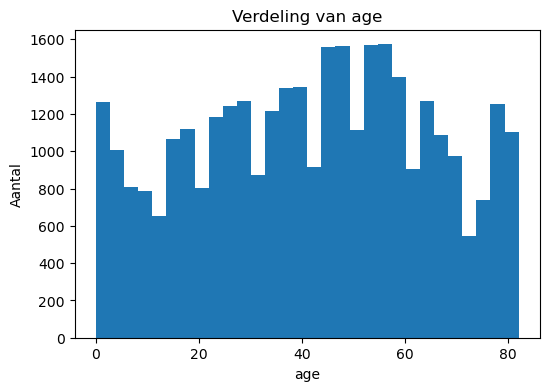

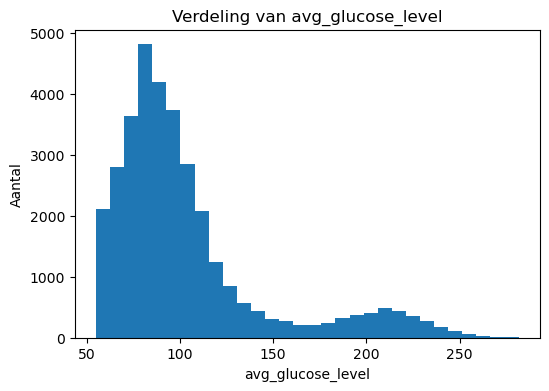

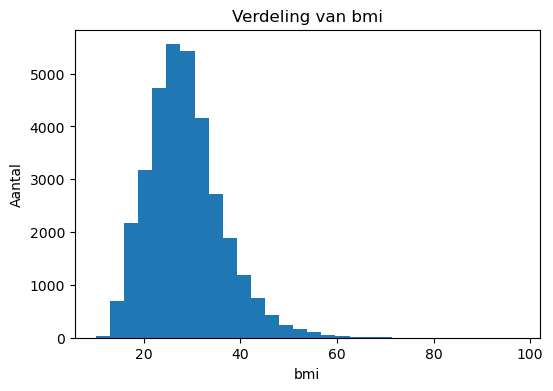

In [10]:
for kol in numerieke_kolommen:
    plt.figure(figsize=(6, 4))
    plt.hist(train[kol].dropna(), bins=30)
    plt.title(f'Verdeling van {kol}')
    plt.xlabel(kol)
    plt.ylabel('Aantal')
    plt.show()

## 1.6 Verdeling Target Kolom (Stroke)

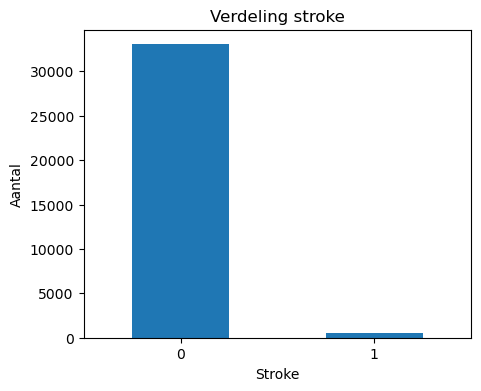

stroke
0    98.459016
1     1.540984
Name: proportion, dtype: float64


In [11]:
stroke_verdeling = train['stroke'].value_counts()

plt.figure(figsize=(5, 4))
stroke_verdeling.plot(kind='bar')

plt.title('Verdeling stroke')
plt.xlabel('Stroke')
plt.ylabel('Aantal')
plt.xticks(rotation=0)

plt.show()

print(train['stroke'].value_counts(normalize=True) * 100)

## 1.7 Correlaties met Target Kolom

In [12]:
correlaties = train.corr()['stroke'].drop('stroke')

correlaties = correlaties.reindex(
    correlaties.abs().sort_values(ascending=False).index
)

display(correlaties)

age                               0.148722
heart_disease                     0.104625
hypertension                      0.084019
avg_glucose_level                 0.076813
ever_married_Yes                  0.066403
ever_married_No                  -0.066403
work_type_Self-employed           0.061883
work_type_children               -0.050728
smoking_status_formerly smoked    0.034092
bmi                               0.020574
smoking_status_never smoked       0.009896
gender_Male                       0.008774
gender_Female                    -0.008727
smoking_status_smokes             0.008489
work_type_Never_worked           -0.008127
work_type_Private                -0.004937
work_type_Govt_job               -0.004439
Residence_type_Urban              0.002654
Residence_type_Rural             -0.002654
gender_Other                     -0.001673
id                                0.000691
Name: stroke, dtype: float64

### 1.7.1 Visualisatie

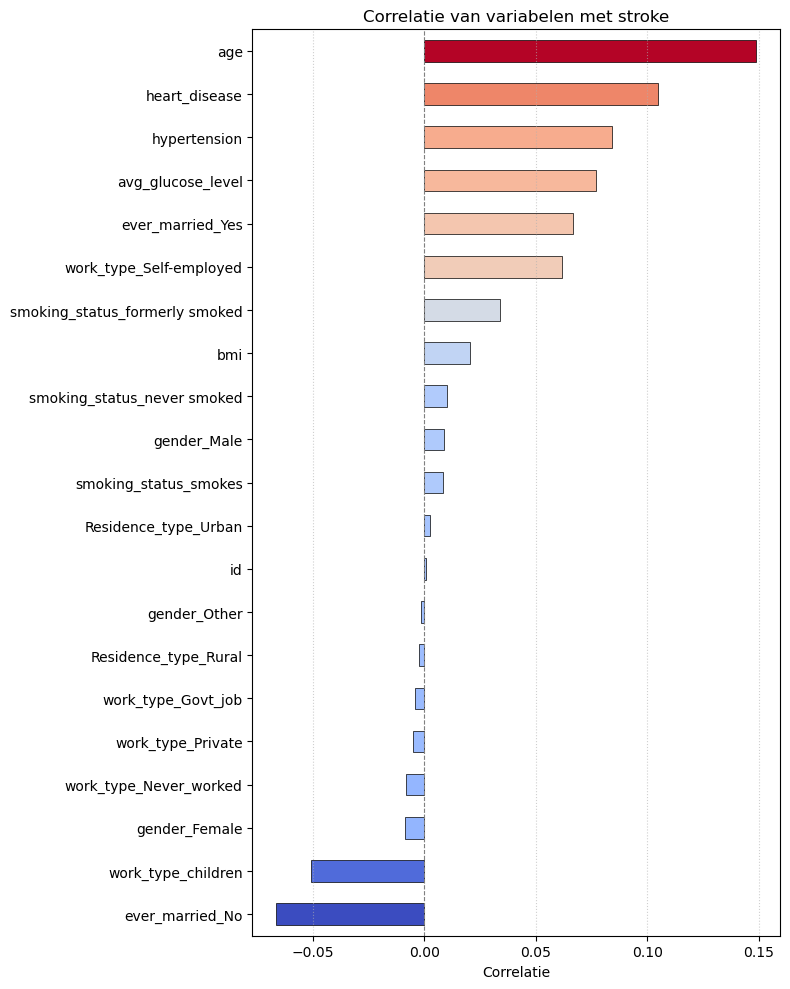

In [13]:
plt.figure(figsize=(8, 10))

data = correlaties.sort_values()

# Schaalt de waarden naar een colormap (bijv. van -1 naar 1 of min/max van de data)
norm = mcolors.Normalize(vmin=data.min(), vmax=data.max())
cmap = cm.coolwarm
kleuren = cmap(norm(data.values))

data.plot(kind='barh', color=kleuren, edgecolor='black', linewidth=0.5)

plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')
plt.title('Correlatie van variabelen met stroke')
plt.xlabel('Correlatie')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

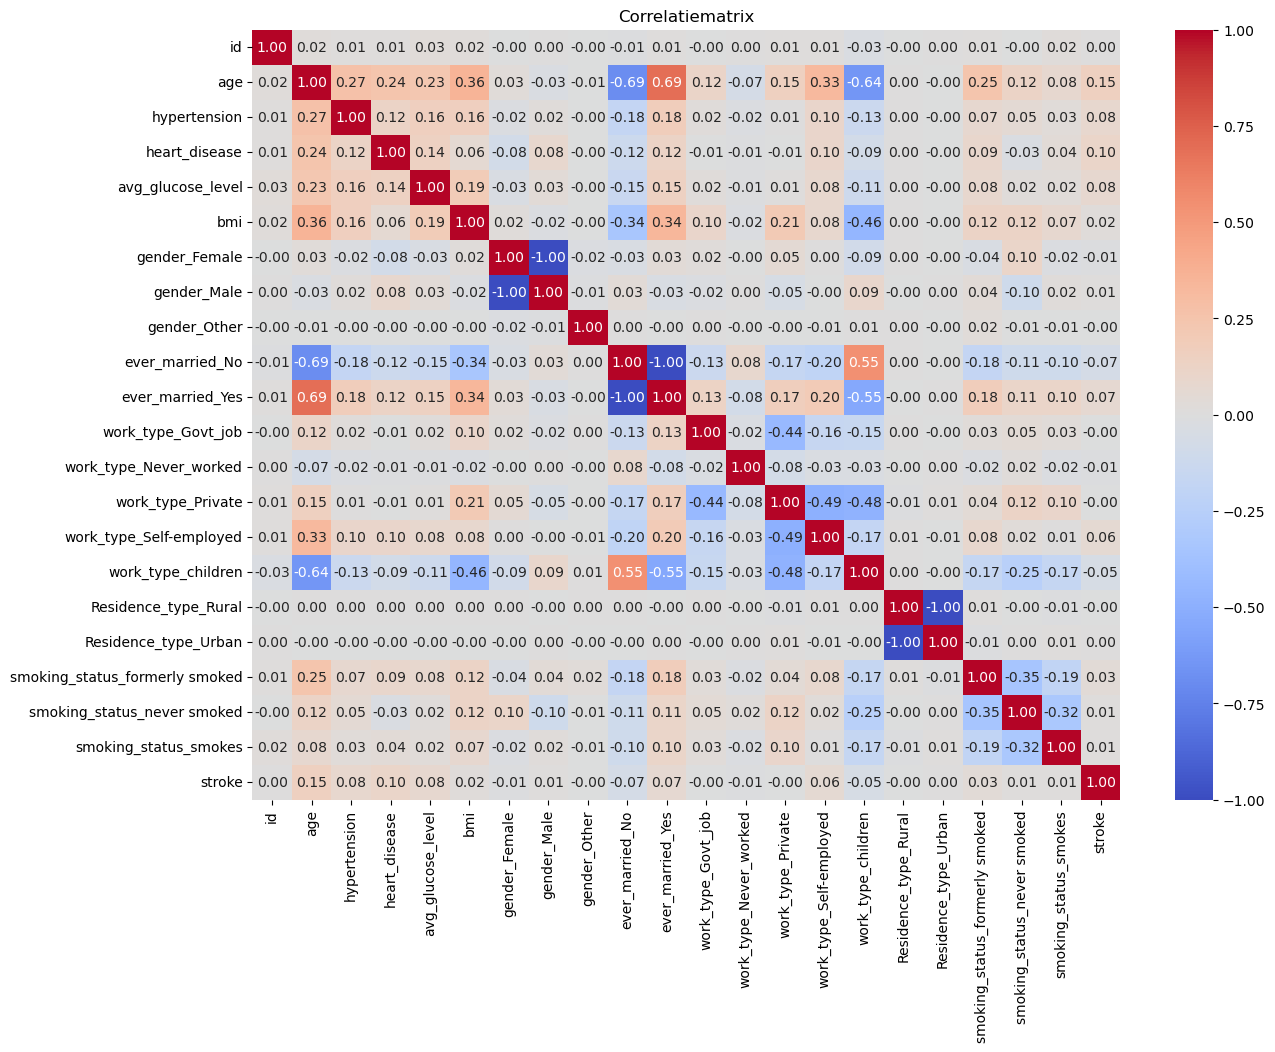

In [14]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    train.corr(),
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
)

plt.title('Correlatiematrix')
plt.show()

## 1.8 Boxplots (Outliers)

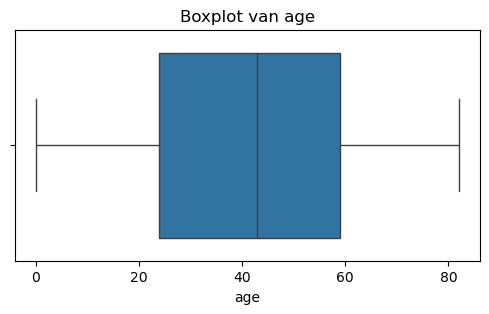

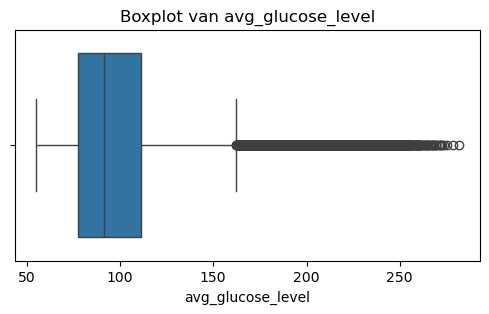

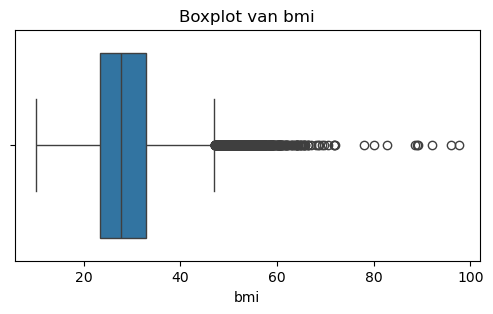

In [15]:

for kol in numerieke_kolommen:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=train[kol])
    plt.title(f'Boxplot van {kol}')
    plt.show()

## 1.9 Belangrijkste Bevindingen

#### **Imbalanced target**

We zien dat van de 33.550 patienten maar slechts 517 (1,54%) een stroke heeft gehad. Dit betekent dat de dataset sterk imbalanced is. Als ons model altijd "Geen Stroke" voorspelt zou het al ongeveer 98,5% accuracy behalen zonder daadwerkelijk iets te leren. Accuracy is daarom bij deze dataset geen geschikte metric om de prestaties van het model goed te beoordelen. Dit is ook de reden waarom in de opdracht de F1-score gebruikt wordt. Later in de opdracht moeten we daarom goed kijken hoe we met deze imbalance omgaan ([scikit-learn developers, z.d.-m](https://scikit-learn.org/stable/modules/model_evaluation.html)).

#### **Geen missende waardes**

Er zijn geen missende waardes aanwezig in de dataset. Hierdoor hoeven we geen extra stappen uit te voeren om ontbrekende data te verwijderen of in te vullen ([scikit-learn developers, z.d.-n](https://scikit-learn.org/stable/modules/impute.html)).

#### **Age, heart_disease, avg_glucose_level en hypertension zijn de meest gecorreleerde aan stroke**

Van de variabelen heeft age de sterkste correlatie met stroke, met een correlatie van ongeveer 0,15. Daarnaast zien we ook een correlatie tussen stroke met: heart_disease, avg_glucose_level en hypertension. Deze correlaties zijn echter nog steeds relatief zwak. Dit laat zien dat geen van deze afzonderlijke variabelen op zichzelf een sterke relatie hebben met stroke ([SciPy developers, z.d.-b](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html)).

#### **BMI en categorische waarden hebben weinig voorspellende waarde**

We zien dat het BMI, gender, woonplaats, werktype en rookstatus allemaal zwakke correlaties met stroke laten zien. Op basis van onze verwachtingen hadden we vooral bij rookstatus een sterke correlatie verwacht. Dat de correlatie laag is betekent niet meteen dat roken geen invloed heeft op het risico van een stroke ([SciPy developers, z.d.-b](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html)).

#### **Uitschieters**

Uit de boxplots blijkt dat BMI en avg_glucose_level relatief veel uitschieters bevatten. Dit zijn waarschijnlijk geen foutieve waardes maar realistische metingen ([Matplotlib developers, z.d.-a](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html)).

## 1.10 Niet relevante kolommen

### 1.10.1 Identificerende kolom (ID)

De ID kolom is een administratief identificatie nummer zonder voorspellende waarde. De correlatie was ook al ~0,0007.
We bewaren alleen de test-ids voor de submission op kaggle, maar halen deze eruit zodat het model niet verward wordt met het trainen en testen.

In [16]:
tests_ids = test['id']

train = train.drop(columns=['id'])
test = test.drop(columns=['id'])

print("Nieuwe vorm train:", train.shape)
print("Nieuwe vorm test:", test.shape)

Nieuwe vorm train: (33550, 21)
Nieuwe vorm test: (8388, 20)


### 1.10.2 Dubbele one-hot-kolommen

De categorische variabelen in de dataset zijn al one-hot-gecodeerd, dat betekend dat onze gecategoriseerde variabelen opgesplitst worden in 0/1 kolommen. De kolommen *`ever_married_Yes`* en *`ever_married_No`* tellen bijvoorbeeld samen altijd op tot 1. Dit betekend dat voor de meeste kolommen een overbodig is. Als iemand al getrouwd is *`ever_married_Yes`* 1 is dan weten we dat *`ever_married_No`* 0 is ([scikit-learn developers, z.d.-l](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)).

Deze dubbele kolommen zijn om twee redenen een probleem:

- **KNN**: Als een categorie verandert dan veranderen er twee kolommen. Daardoor is het verschil groter dan het eigenlijk is ([scikit-learn developers, z.d.-k](https://scikit-learn.org/stable/modules/neighbors.html)).
- **Logistic Regression**: De kolommen hangen sterk van elkaar af. Hierdoor is het moeilijker om te bepalen welke kolom precies invloed heeft op de uitkomst ([scikit-learn developers, z.d.-l](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)).

Voor Decision Trees maakt het weinig verschil uit, maar ze verliezen hierdoor geen informatie. Daarom verwijderen we de kolommen bij alle modelen.

Per groep laten we een categorie weg. Deze categorie is de referentie. Als alle andere categorieen 0 zijn hoort de patient bij de referentiecategorie ([scikit-learn developers, z.d.-l](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)). We kiezen:

| Groep | Weggehaald | Reden |
|---|---|---|
| *`ever_married`* | *`ever_married_No`* | Als iemand getrouwd is zie je meteen 1 of 0 |
| *`gender`* | *`gender_Female`* | grootste groep, dus logische referentie |
| *`work_type`* | *`work_type_Never_worked`* | maar 141 patiënten en geen enkele stroke |
| *`Residence_type`* | *`Residence_type_Rural`* | willekeurig, beide groepen even groot |

*`smoking_status`* laten we hetzelfde. De kolommen tellen niet altijd op tot 1. Bij 10.320 patienten zijn alle 3 kolommen 0.

In [17]:
smoking_cols = [col for col in train.columns if col.startswith('smoking_status_')]

# Aantal patienten waarbij alle rookkolommen 0 zijn ('Unknown')
print((train[smoking_cols].sum(axis=1) == 0).sum())

10320


In [18]:
# Kolommen per one-hot-groep
one_hot_groups = {
    'ever_married': ['ever_married_No', 'ever_married_Yes'],
    'gender': ['gender_Female', 'gender_Male', 'gender_Other'],
    'work_type': ['work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children'],
    'Residence_type': ['Residence_type_Rural', 'Residence_type_Urban'],
    'smoking_status': ['smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes'],
}

# Controle: tellen de kolommen per rij altijd op tot 1?
for group, columns in one_hot_groups.items():
    print(group, train[columns].sum(axis=1).value_counts())

ever_married 1    33550
Name: count, dtype: int64
gender 1    33550
Name: count, dtype: int64
work_type 1    33550
Name: count, dtype: int64
Residence_type 1    33550
Name: count, dtype: int64
smoking_status 1    23230
0    10320
Name: count, dtype: int64


### Conlusie

We zien dat de categorieën van `ever_married`, `gender`, `work_type` en `Residence_type` voor alle 33.550 patienten precies een waarde hebben. Hiervan kunnen we ze dus veilig verwijderen.

Bij `smoking_status` is dit anders. Bij 23.230 patienten is een van de drie categorieën ingevuld. Bij 10.320 patienten zijn alle drie de kolommen 0. 

In [19]:
# Per groep één kolom weghalen (de referentiecategorie)
redundant_cols = [
    'ever_married_No',
    'gender_Female',
    'work_type_Never_worked',
    'Residence_type_Rural',
]

train = train.drop(columns=redundant_cols)
test = test.drop(columns=redundant_cols)

print("Nieuwe vorm train:", train.shape)
print("Nieuwe vorm test:", test.shape)

Nieuwe vorm train: (33550, 17)
Nieuwe vorm test: (8388, 16)


### 1.10.3 Woongebied

Na 1.10.2 is van het woongebied alleen *`Residence_type_Urban`* over (1 = stad, 0 = platteland). Als we terug kijken naar 1.7 zi.en we dat deze variabel bijna geen correlatie heeft met stroke (0,003). We kunnen de p-waarde berekeken van deze kolom om te kijken of het toeval is of niet ([SciPy developers, z.d.-a](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html)).

Als we naar het resultaat hieronder kijken zien we dat de p-waarde 0,66 is. Dit laat zien dat er geen statistisch significant verband is tussen woongebied en beroerte ([SciPy developers, z.d.-a](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html)).

Omdat het woongebied geen duidelijk verband met *`stroke`* laat zien, verwijderen we deze kolom. Vooral bij KNN is dit handig, omdat een kolom zonder verband met de target wel meetelt in de afstand tussen patienten en daardoor extra ruis kan veroorzaken ([scikit-learn developers, z.d.-k](https://scikit-learn.org/stable/modules/neighbors.html)).

In [20]:


table = pd.crosstab(train['Residence_type_Urban'], train['stroke'])

p_value = chi2_contingency(table)[1]

print(f"p-waarde: {p_value:.2f}")

# Kolom verwijderen
train = train.drop(columns='Residence_type_Urban')
test = test.drop(columns='Residence_type_Urban')

print("Nieuwe vorm train:", train.shape)
print("Nieuwe vorm test:", test.shape)

p-waarde: 0.66
Nieuwe vorm train: (33550, 16)
Nieuwe vorm test: (8388, 15)


### 1.10.4 Zeldzame categorieën

Bij categorieen met maar weinig patienten kan een model moeilijk een betrouwbaar patroon leren. Daarom kijken we hoeveel patienten er per categorie zijn en hoeveel daarvan een beroerte hebben gehad. 

- **`gender_Other`**: 6 patiënten, waarvan geen enkele een beroerte heeft gehad. Als we deze kolom verwijderen worden deze patienten automatisch bij `gender_Female` ingedeeld. Daar is geen goede reden voor. Omdat er maar 6 patienten zijn in deze categorie, verwachten we weinig invloed op de modellen. Dus laten we deze kolom staan.

De overige categorieën bevatten allemaal duizenden patiënten en vormen daarom geen probleem.

In [21]:
# Stroke bij de patiënten met gender_Other
display(train.loc[train['gender_Other'] == 1, 'stroke'].value_counts())

stroke
0    6
Name: count, dtype: int64

### 1.10.5 Rookstatus

Bij `smoking_status` zijn er 10.320 patienten waarbij alle 3 kolommen 0 zijn. Dit is de categorie `unknown`. Er zijn 2 redenen waarom we deze kolommen niet weghalen, door de hoge correlatie en omdat het model "nooit gerookt" en `unknown` niet meer goed kan onderscheiden. Een aparte kolom voor `unknown` is ook niet nodig omdat dit te zien is aan 3 nullen bij de andere kolommen.

In de cel hieronder vergelijken we de rookcategorieen tegenover de leeftijd. `Unknown` heeft met 0,72% de laagste percentage een stroke. Dit komt waarschijnlijk omdat deze groep jonger is (mediane leeftijd is 20 jaar), dit zijn dus waarschijnlijk jongeren die nog nooit gerookt hebben maar ook niks hebben ingevuld. `Formerly_smoked` heeft met 2,47% het hoogste percentage, maar dit is ook de oudste groep (mediane leeftijd is 56 jaar). Leeftijd speelt waarschijnlijk een belangrijke rol tussen de rookcategorieen.

In [22]:
smoking_cols = [col for col in train.columns if col.startswith('smoking_status_')]

# Rookcategorie per patient, 'Unknown' als alle kolommen 0 zijn
smoking_status = train[smoking_cols].idxmax(axis=1).where(train[smoking_cols].sum(axis=1) == 1, 'Unknown')

# Per categorie: aantal patienten, % stroke en mediane leeftijd
display(train.groupby(smoking_status).agg(
    patienten=('stroke', 'size'),
    stroke_pct=('stroke', 'mean'),
    mediane_leeftijd=('age', 'median'),
))

,patienten,stroke_pct,mediane_leeftijd
Unknown,10320,0.007171,20.0
smoking_status_formerly smoked,5661,0.024731,56.0
smoking_status_never smoked,12602,0.016981,45.0
smoking_status_smokes,4967,0.017918,46.0


## 1.11 Standaardisatie van de data

Bij standaardisatie wordt voor iedere numerieke variabele het gemiddelde afgetrokken en wordt het resultaat gedeeld door de standaardafwijking: $z = \frac{x - \mu}{\sigma}$. De getransformeerde variabele heeft daardoor op de trainingsdata een gemiddelde van ongeveer 0 en een standaardafwijking van ongeveer 1. `StandardScaler` voert deze berekening per variabele uit. De methode is gevoelig voor uitschieters, omdat het gemiddelde en de standaardafwijking door extreme waarden worden beïnvloed ([scikit-learn developers, z.d.-a](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)).

### Waarom standaardiseren voor deze dataset?

De continue variabelen hebben duidelijk verschillende schalen. `age` loopt van 0,08 tot 82, `avg_glucose_level` van 55,01 tot 281,59 en `bmi` van 10,10 tot 97,60. Zonder standaardisatie kan een variabele met grotere numerieke verschillen zwaarder meetellen, ook als die inhoudelijk niet belangrijker is. Dit is vooral relevant voor K-Nearest Neighbors, omdat afstanden de voorspelling bepalen. De officiële scikit-learn-documentatie laat zien dat schalen bij KNN een andere neighbour structuur en beslisgrens kan opleveren. Schalen is ook relevant voor SVM en Logistic Regression; bij Logistic Regression convergeren de `sag`- en `saga`-solvers alleen betrouwbaar snel wanneer kenmerken ongeveer dezelfde schaal hebben ([scikit-learn developers, z.d.-b](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html); [scikit-learn developers, z.d.-c](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)).

### Gekozen werkwijze

We standaardiseren alleen de continue variabelen `age`, `avg_glucose_level` en `bmi` met `StandardScaler`. De binaire en one-hot-gecodeerde variabelen blijven 0 of 1. Voor KNN, Logistic Regression en SVM gebruiken we de onderstaande preprocessing in een `Pipeline`. Decision Tree, Random Forest, Gradient Boosted Decision Trees en XGBoost zijn boommodellen en worden vrijwel niet beïnvloed door schaling; voor deze modellen gebruiken we daarom de oorspronkelijke waarden ([scikit-learn developers, z.d.-b](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)).

De scaler wordt hier alleen als herbruikbare pipeline gedefinieerd en nog niet op de volledige dataset gefit. Tijdens cross-validation moet `fit` uitsluitend op de trainingsfold worden uitgevoerd. Een pipeline zorgt ervoor dat het gemiddelde en de standaardafwijking per trainingsfold worden geleerd en voorkomt dat informatie uit de validatie- of testdata lekt ([scikit-learn developers, z.d.-d](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)).

Omdat de boxplots uitschieters tonen, vergelijken we later tijdens cross-validation `StandardScaler` eventueel met `RobustScaler`. We kiezen `StandardScaler` als onderbouwde basisinstelling, maar bepalen op basis van validatieresultaten of een robuust alternatief werkelijk beter presteert.

In [23]:
# Prompt 5: Standaardisatie (OpenAI Codex; zie AI-referentielijst).

numeric_cols = [
    'age',
    'avg_glucose_level',
    'bmi',
]

# Laat zien hoever de schalen van deze variabelen uit elkaar liggen
scale_summary = (
    train[numeric_cols]
    .agg(['min', 'max', 'mean', 'std'])
    .T
    .round(2)
)

display(scale_summary)


def make_scaled_pipeline(model):
    """
    Pipeline voor de modellen die gevoelig zijn voor schaal. (KNN, LR, SVM).
    """
    preprocessor = ColumnTransformer(
        transformers=[
            (
                'scale',
                StandardScaler(),
                numeric_cols,
            ),
        ],
        remainder='passthrough',
        verbose_feature_names_out=False,
    )

    return Pipeline(
        steps=[
            ('preprocessing', preprocessor),
            ('model', model),
        ]
    )

,min,max,mean,std
age,0.08,82.00,41.82,22.48
avg_glucose_level,55.01,281.59,103.59,42.13
bmi,10.10,97.60,28.60,7.78


De numerieke kenmerken hebben duidelijk verschillende schalen. Vooral avg_glucose_level heeft een grotere standaardafwijking dan bmi. Bij afstandsgebaseerde en schaalgevoelige modellen kan hierdoor één kenmerk onevenredig veel invloed krijgen. Daarom standaardiseren we age, avg_glucose_level en bmi voor KNN, Logistic Regression en SVM. De standaardisatie vindt binnen de modelpipeline plaats, zodat het gemiddelde en de standaardafwijking uitsluitend uit de betreffende trainingsdata worden berekend. De binaire kenmerken blijven ongewijzigd.

# 2. Evaluatie

In dit hoofdstuk bepalen we met passende classificatiemetrics hoe goed de modellen presteren.

## 2.1 Train- en validatiestrategie

We splitsen de gelabelde dataset in 80% trainingsdata en 20% validatiedata met *`train_test_split`*. Hierbij gebruiken we *`random_state=42`* voor reproduceerbaarheid en *`stratify=y`* om de verhouding tussen patiënten met en zonder stroke ongeveer gelijk te houden ([scikit-learn developers, z.d.-i](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)).

Op de trainingsdata voeren we 5-fold stratified cross-validation uit. Hierbij wordt het model vijf keer getraind op vier folds en geëvalueerd op de overgebleven fold ([scikit-learn developers, z.d.-e](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)).

Met *`GridSearchCV`* vergelijken we verschillende hyperparameters op basis van de gemiddelde F1-score. Daarnaast gebruiken we *`TunedThresholdClassifierCV`* met een interne 3-fold cross-validation om de beslisdrempel te optimaliseren ([scikit-learn developers, z.d.-f](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html); [scikit-learn developers, z.d.-j](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html)).

Standaardisatie en sampling bevinden zich binnen de modelpipelines, zodat deze tijdens cross-validation alleen op de betreffende trainingsfolds worden toegepast ([imbalanced-learn developers, z.d.-a](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html)).

Na de modelselectie beoordelen we het model op de apart gehouden validatieset. Voor de uiteindelijke Kaggle-submission trainen we de gekozen pipeline opnieuw op de volledige gelabelde dataset.

In [24]:


X = train.drop(columns="stroke")
y = train["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

print("Traindata:", X_train.shape)
print("Testdata:", X_test.shape)
print("\nStroke-verhouding traindata:")
display(y_train.value_counts(normalize=True).mul(100).round(3))
# .mul = Equivalent to ``dataframe * other``, but with support to substitute a fill_value for missing data in one of the inputs. With reverse version, rmul.
print("\nStroke-verhouding testdata:")
display(y_test.value_counts(normalize=True).mul(100).round(3))

Traindata: (26840, 15)
Testdata: (6710, 15)

Stroke-verhouding traindata:


stroke
0    98.458
1     1.542
Name: proportion, dtype: float64


Stroke-verhouding testdata:


stroke
0    98.465
1     1.535
Name: proportion, dtype: float64

Op de train data gebruiken we 5-fold stratified cross-validation. Bij iedere ronde traint het model op vier folds en evalueren we het op de overgebleven fold. Zo gebruiken we het grootste deel van de ontwikkeldata voor training en validatie, terwijl de klasseverhouding per fold ongeveer gelijk blijft. We gebruiken dezelfde folds en F1-score voor de vergelijking en tuning van alle modellen. 



## 2.2 Evaluatiemetrics en confusion matrix

Om de eerste evaluatie te maken gebruiken we Logistic Regression als baseline. Omdat de stroke class maar 1,54% van de data is, geven we de minderheidsklasse met `class_weight='balanced'` extra gewicht. Dit is een eerste aanpak tegen de onbalans, in hoofdstuk 3 vergelijken we meerdere technieken. De baseline wordt op de ontwikkeldata getraind en op de apart gehouden eindvalidatieset beoordeeld.

De confusion matrix vergelijkt de werkelijke klasse met de voorspelde klasse. Bij labels 0 en 1 gebruikt scikit-learn de volgorde `[[TN, FP], [FN, TP]]`: true negatives (TN) zijn correct herkende patiënten zonder stroke, false positives (FP) zijn patiënten zonder stroke die ten onrechte positief zijn voorspeld, false negatives (FN) zijn gemiste strokes en true positives (TP) zijn correct herkende strokes.

We rapporteren de volgende maten ([scikit-learn developers, z.d.-p](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)):

- **Accuracy** $= \frac{TP + TN}{TP + TN + FP + FN}$: het aandeel correcte voorspellingen. Door de sterke klasse-onbalans kan deze maat hoog zijn terwijl het model bijna alle strokes mist.
- **Precision** $= \frac{TP}{TP + FP}$: van de patiënten die het model als stroke aanwijst, welk aandeel had volgens de labels daadwerkelijk een stroke? Een lage precision betekent relatief veel fout-positieve signalen.
- **Recall (sensitiviteit)** $= \frac{TP}{TP + FN}$: van de patiënten met stroke, welk aandeel vindt het model? Een lage recall betekent dat het model veel strokes mist.
- **F1-score** $= 2 \cdot \frac{precision \cdot recall}{precision + recall}$: het harmonisch gemiddelde van precision en recall. F1 is laag wanneer één van beide laag is, maar houdt geen rekening met true negatives.

Dit zijn classificatiematen op basis van de beschikbare labels; ze tonen op zichzelf niet aan dat het model geschikt is voor klinisch gebruik. We interpreteren de fout-positieve en fout-negatieve voorspellingen daarom afzonderlijk.

,Metric,Score
0,Accuracy,0.753
1,Precision,0.049
2,Recall,0.825
3,F1-score,0.093


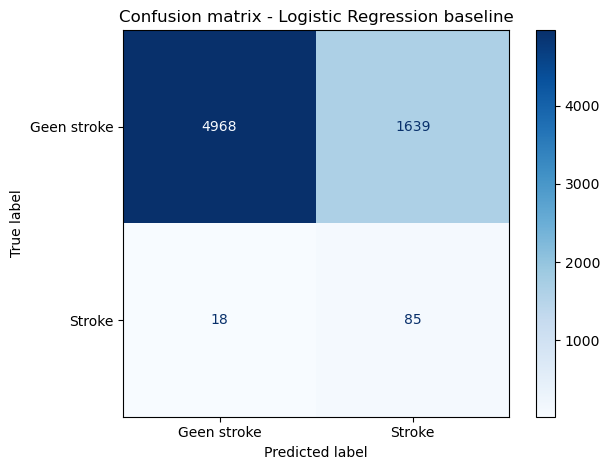

In [25]:


baseline_model = make_scaled_pipeline(
    LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42,
    )
)

baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

baseline_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Score': [
        accuracy_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred_baseline, zero_division=0),
        recall_score(y_test, y_pred_baseline, zero_division=0),
        f1_score(y_test, y_pred_baseline, zero_division=0),
    ],
})

display(baseline_metrics.round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseline,
    labels=[0, 1],
    display_labels=['Geen stroke', 'Stroke'],
    values_format='d',
    cmap='Blues',
)
plt.title('Confusion matrix - Logistic Regression baseline')
plt.tight_layout()
plt.show()

**Interpretatie van de confusion matrix**

Bij ons eerste Logistic Regression-baselinemodel krijgen we de volgende resultaten:

- **True negatives (TN): 4.968.** Het model voorspelt correct dat deze patiënten geen stroke hebben gehad.
- **False positives (FP): 1.639.** Het model voorspelt een stroke, terwijl de werkelijke klasse 0 is.
- **False negatives (FN): 18.** Het model voorspelt geen stroke, terwijl de werkelijke klasse 1 is.
- **True positives (TP): 85.** Het model herkent deze patiënten met stroke correct.

De recall is ongeveer 82,5%. Het model vindt dus een groot deel van de echte strokegevallen. De precision is wel maar 4,9%. Dit betekent dat een groot deel van de positieve voorspellingen false positive is.

De F1-score komt daardoor uit op ongeveer 0,093. Het model herkent veel strokes, maar maakt tegelijkertijd veel false positives.

Hieruit blijkt waarom we zowel precision als recall moeten bekijken. Alleen een hoge recall is niet voldoende om te concluderen dat een model goed presteert.

## 2.3 Keuze voor de F1-score

Voor deze classificatietaak wordt de F1-score gebruikt omdat de dataset sterk ongebalanceerd is: er zijn veel meer mensen zonder beroerte dan met een beroerte. Hierdoor kan accuracy een vertekend beeld geven van hoe goed het model daadwerkelijk presteert.

De F1-score combineert precision en recall. Precision geeft aan hoeveel voorspelde beroertes daadwerkelijk correct zijn, terwijl recall aangeeft hoeveel van de echte beroertes door het model worden gevonden. Beide zijn hier belangrijk. Een false positive betekent dat iemand onterecht als beroertegeval wordt voorspeld, terwijl bij een false negative een werkelijk beroertegeval wordt gemist. De F1-score zorgt ervoor dat het model een balans moet vinden tussen deze twee soorten fouten.

Bron: ([Google developers, z.d.-a](https://developers.google.com/machine-learning/crash-course/classification/accuracy-precision-recall))

# 3. Modelleren en uitleg modellen

Voor ieder model passen we cross-validation en hyperparametertuning toe. Met de beste hyperparameters maken we voorspellingen voor `test.csv` en uploaden we een eigen submission naar Kaggle. Per model vergelijken we minimaal twee passende technieken voor de ongebalanceerde target en leggen we de werking daarvan uit.

## 3.1 Algemene modelaanpak

Voor alle modellen gebruiken we dezelfde 5-fold stratified cross-validation. Met *`GridSearchCV`* proberen we verschillende hyperparameters uit. We kiezen de instellingen met de hoogste gemiddelde F1-score ([scikit-learn developers, z.d.-e](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html); [scikit-learn developers, z.d.-f](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)).

Per model vergelijken we minimaal twee technieken om met de onbalans om te gaan. Standaardisatie en eventuele resampling zetten we in een pipeline, zodat deze stappen alleen op de trainingsdata van iedere fold worden uitgevoerd. Schalen gebruiken we bij KNN, Logistic Regression en SVM. De desiciontrees hebben dit niet nodig ([imbalanced-learn developers, z.d.-a](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html); [scikit-learn developers, z.d.-b](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)).

Van ieder model noteren we de beste hyperparameters en de F1-score uit cross-validation. Daarna beoordelen we het model op de apart gehouden validatieset en maken we met het gekozen model een submission voor Kaggle.

### Technieken voor de ongebalanceerde dataset

Onze dataset bevat ongeveer 1,54% patiënten met een stroke. Hierdoor kan een model een hoge accuracy behalen door bijna altijd klasse 0 te voorspellen. Om dit te verbeteren onderzoeken we verschillende technieken.

**RandomOverSampler** brengt de klassen meer in balans door willekeurig voorbeelden uit de minderheidsklasse opnieuw te gebruiken. Hierdoor krijgt de stroke klasse meer invloed tijdens het trainen. Er ontstaat echter geen nieuwe informatie, waardoor het model gevoeliger kan worden voor overfitting ([imbalanced-learn developers, z.d.-b](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.RandomOverSampler.html)).

**RandomUnderSampler** brengt de klassen meer in balans door willekeurig voorbeelden uit de meerderheidsklasse te verwijderen. Hierdoor wordt de stroke klasse relatief belangrijker, maar gaat ook informatie over patiënten zonder stroke verloren ([imbalanced-learn developers, z.d.-c](https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.RandomUnderSampler.html)).

**Class weights** passen het gewicht van trainingsvoorbeelden aan. Fouten op voorbeelden uit de minderheidsklasse kunnen hierdoor zwaarder worden bestraft. We onderzoeken deze methode onder andere bij Random Forest ([scikit-learn developers, z.d.-g](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)).

**Beslisdrempeloptimalisatie** verandert vanaf welke score het model klasse 1 voorspelt ([scikit-learn developers, z.d.-h](https://scikit-learn.org/stable/modules/classification_threshold.html)).

### Resultaten en submissions

- De functie toon_resultaten laat na de gridsearch de beste parameters, beslisdrempel, CV-F1 en metrics op onze validatieset zien. De confusion matrix staat bij ieder model.
- De functie maak_submission traint alleen de gekozen pipeline opnieuw op alle ontwikkeldata. De beslisdrempel blijft gelijk; we tunen die hier niet opnieuw.
- We gebruiken dezelfde soort score als de drempeltuning: kansen bij KNN/LR/Tree/RF en decision_function bij onze SVM.
- De functie controleert de kolommen, labels, aantallen en id-volgorde en slaat de CSV zonder extra index op.
- De aanroepen staan bewust Raw. Zet een submissioncel pas naar Code en voer die uit nadat de bijbehorende training klaar is.
- Nieuwe bestanden krijgen _nieuw in de naam, zodat eerdere Kaggle-submissions niet worden overschreven. Een eerdere Kaggle-score hoort niet automatisch bij een nieuwe CSV.



In [26]:
# Prompt 26: KNN, SVM en herbruikbare functies (OpenAI Codex).
# AI-ondersteuning, 8 oktober 2026; zie de AI-referentielijst.

def toon_resultaten(zoekopdracht):
    """Toon de beste instellingen en scores op onze validatieset."""
    model = zoekopdracht.best_estimator_
    voorspellingen = model.predict(X_test)

    print("Beste instellingen:", zoekopdracht.best_params_)
    print("Beslisdrempel:", round(model.best_threshold_, 6))
    print("CV-F1:", round(zoekopdracht.best_score_, 4))

    metrics = {
        "Accuracy": accuracy_score(y_test, voorspellingen),
        "Precision": precision_score(y_test, voorspellingen, zero_division=0),
        "Recall": recall_score(y_test, voorspellingen, zero_division=0),
        "F1": f1_score(y_test, voorspellingen, zero_division=0),
    }
    display(pd.Series(metrics, name="Validatiescore").round(4))


def maak_submission(model, X, y, test, test_ids, bestandsnaam):
    """Train de gekozen pipeline opnieuw en bewaar de Kaggle-voorspellingen."""
    if not X.columns.equals(test.columns):
        raise ValueError("Train- en testfeatures moeten dezelfde volgorde hebben.")

    voorbeeld = pd.read_csv("../data/sample_submission.csv")
    if len(voorbeeld) != len(test):
        raise ValueError("Het aantal testregels past niet bij de voorbeeldsubmission.")
    if not voorbeeld["id"].equals(test_ids.reset_index(drop=True)):
        raise ValueError("De test-id's staan niet in de juiste volgorde.")

    # Clone alleen de pipeline: de gekozen drempel wordt niet opnieuw getuned.
    drempel = model.best_threshold_
    definitief_model = clone(model.estimator_)
    definitief_model.fit(X, y)

    if not np.array_equal(definitief_model.classes_, [0, 1]):
        raise ValueError("De modelklassen moeten 0 en 1 zijn.")

    score_methode = model.response_method
    if score_methode == "auto":
        if hasattr(definitief_model, "predict_proba"):
            score_methode = "predict_proba"
        else:
            score_methode = "decision_function"

    if score_methode == "predict_proba":
        scores = definitief_model.predict_proba(test)[:, 1]
    elif score_methode == "decision_function":
        scores = definitief_model.decision_function(test)
    else:
        raise ValueError("Onbekende scoremethode.")

    if len(scores) != len(test) or not np.isfinite(scores).all():
        raise ValueError("De voorspelde scores zijn onvolledig of ongeldig.")

    voorspellingen = (scores >= drempel).astype(int)
    submission = voorbeeld.copy()
    submission["stroke"] = voorspellingen
    submission.to_csv(bestandsnaam, index=False)

    print("Opgeslagen:", bestandsnaam)
    print("Scoremethode:", score_methode)
    print("Gebruikte drempel:", round(drempel, 6))
    print("Aantal positieve voorspellingen:", voorspellingen.sum())
    return submission


## 3.2 K-Nearest Neighbors

KNN kijkt naar de k dichtstbijzijnde datapunten. Deze buren bepalen de voorspelling. Hoe we de afstand berekenen hangt af van p ([scikit-learn developers, z.d.-k](https://scikit-learn.org/stable/modules/neighbors.html)).

### Afstandsberekening

- **Euclidisch (p=2):** de rechte afstand tussen twee punten.

$$
d_E(x,z) = \sqrt{\sum_{j=1}^{m}(x_j-z_j)^2}
$$

- **Manhattan (p=1):** tel de absolute verschillen per kenmerk op.

$$
d_M(x,z) = \sum_{j=1}^{m}|x_j-z_j|
$$

Hierbij zijn $x$ en $z$ twee patiënten en is $m$ het aantal kenmerken.

**Klein rekenvoorbeeld:** neem twee punten met twee al geschaalde kenmerken: $x=(0,0)$ en $z=(3,4)$.

- Euclidisch: $\sqrt{(0-3)^2+(0-4)^2}=\sqrt{25}=5$.
- Manhattan: $|0-3|+|0-4|=3+4=7$.

Dezelfde punten hebben dus een andere afstand, afhankelijk van de gekozen maat. In ons model gebruiken we alle overgebleven kenmerken; dit voorbeeld gebruikt er alleen twee om het simpel te houden ([scikit-learn developers, z.d.-q](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.DistanceMetric.html)).

Standaardisatie is belangrijk, omdat kenmerken op verschillende schalen kunnen staan. Zonder het schalen kan bijvoorbeeld *`avg_glucose_level`* zwaarder meetellen dan *`bmi`*, alleen doordat de waarden groter zijn en niet omdat het belangrijker is. Door te standaardiseren krijgen alle kenmerken een vergelijkbare schaal. Hiervoor gebruiken we de preprocessing pipeline uit 1.11 ([scikit-learn developers, z.d.-b](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)).

KNN heeft geen aparte regularisatieparameter. De complexiteit regelen we vooral met *`n_neighbors`*: weinig buren maakt het model gevoelig voor losse waarnemingen (overfitting), veel buren maakt de voorspellingen algemener (underfitting). Met *`weights`* tellen alle buren even zwaar mee (*`uniform`*) of dichtbije buren zwaarder (*`distance`*). Met *`p`* kiezen we de afstandsmaat: 1 is Manhattan, 2 is Euclidisch ([scikit-learn developers, z.d.-r](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)).

Met *`GridSearchCV`* vergelijken we deze instellingen, samen met RandomOverSampler en RandomUnderSampler. Voor elke combinatie bepalen we ook de beslisdrempel met de hoogste F1-score. We kiezen de combinatie met de hoogste gemiddelde F1-score uit de cross-validation ([scikit-learn developers, z.d.-f](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html); [scikit-learn developers, z.d.-j](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html); [imbalanced-learn developers, z.d.-b](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.RandomOverSampler.html); [imbalanced-learn developers, z.d.-c](https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.RandomUnderSampler.html)).

In [27]:
# Gebruikt de schaalstap uit onze scaled pipeline 
preprocessing = make_scaled_pipeline(KNeighborsClassifier()).named_steps["preprocessing"]

knn_pipeline = ImbPipeline(steps=[
    ("preprocessing", preprocessing),                 # 1. features schalen
    ("sampler", RandomOverSampler(random_state=42)),  # 2. klassen in balans brengen
    ("model", KNeighborsClassifier()),                # 3. het KNN-model zelf
])

# 3 fold CV waarmee de beste beslisdrempel wordt gekozen
threshold_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Zoekt de beslisdrempel met de hoogste F1 score voor de KNN pipeline
knn_with_threshold = TunedThresholdClassifierCV(
    estimator=knn_pipeline,
    scoring="f1",
    cv=threshold_cv,
    store_cv_results=True
)

# Alle combinaties van instellingen die de gridsearch gaat uitproberen
knn_param_grid = {
    "estimator__sampler": [
        RandomOverSampler(random_state=42),   # zorgt ervoor dat de minderheidsklasse (stroke) wordt bijkopieerd
        RandomUnderSampler(random_state=42),  # zorgt ervoor dat de meerderheidsklasse (geen stroke) wordt uitgedund 
    ],
    "estimator__model__n_neighbors": [5, 11, 21],          # aantal buren
    "estimator__model__weights": ["uniform", "distance"],  # alle buren even zwaar, of dichtbij zwaarder
    "estimator__model__p": [1, 2],                         # afstandsmaat: 1 = Manhattan, 2 = Euclidisch
}

# Probeert elke combininatie van de grid en kiest de beste op basis van de F1 score
knn_threshold_search = GridSearchCV(
    estimator=knn_with_threshold,
    param_grid=knn_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)

knn_threshold_search.fit(X_train, y_train)

# Het model met de beste instellingen en threshold
best_model = knn_threshold_search.best_estimator_

y_pred = best_model.predict(X_test)

toon_resultaten(knn_threshold_search)


Beste instellingen: {'estimator__model__n_neighbors': 21, 'estimator__model__p': 1, 'estimator__model__weights': 'distance', 'estimator__sampler': RandomUnderSampler(random_state=42)}
Beslisdrempel: 0.808081
CV-F1: 0.1257


Accuracy     0.9347
Precision    0.0781
Recall       0.3010
F1           0.1240
Name: Validatiescore, dtype: float64

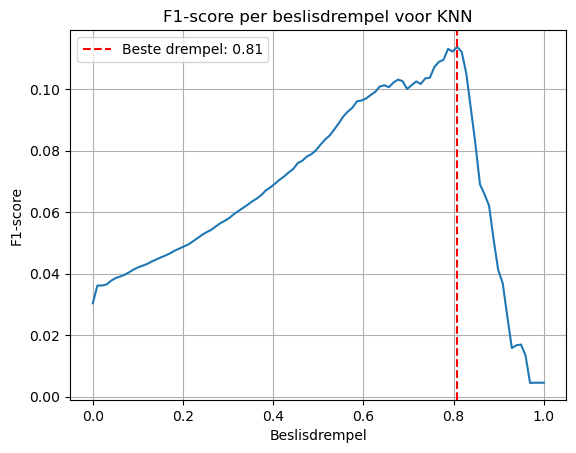

In [28]:
results = best_model.cv_results_
best_threshold = best_model.best_threshold_

plt.plot(results["thresholds"], results["scores"])
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Beste drempel: {round(best_threshold, 2)}")

plt.xlabel("Beslisdrempel")
plt.ylabel("F1-score")
plt.title("F1-score per beslisdrempel voor KNN")
plt.legend()
plt.grid()
plt.show()

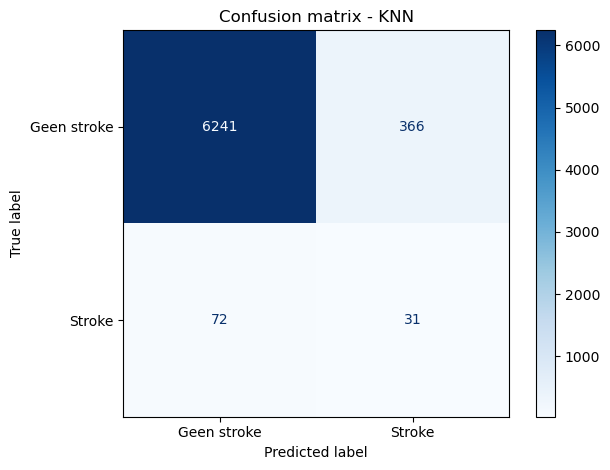

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    cmap="Blues",
)

plt.title("Confusion matrix - KNN")
plt.tight_layout()
plt.show()

### 3.2.3 Resultaten en interpretatie

- **Data:** slechts **1,54%** van de trainingsdata heeft `stroke = 1`. Daarom vergelijken we manieren om met deze onbalans om te gaan.
- **Schaling:** we standaardiseren leeftijd, glucose en BMI. Zo krijgt een kenmerk met grotere getallen niet automatisch meer invloed op de afstand tussen patiënten.
- **Onbalans:** de gridsearch koos `RandomUnderSampler`. Die haalt binnen elke trainingsfold een deel van de voorbeelden zonder stroke weg. De stroke-groep krijgt daardoor meer invloed, maar het model ziet ook minder voorbeelden zonder stroke ([imbalanced-learn developers, z.d.-c](https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.RandomUnderSampler.html)).
- **KNN:** de beste combinatie was **k=21**, **Manhattan-afstand** (`p=1`) en **meer gewicht voor dichtbijzijnde buren** (`weights='distance'`). Dit was de combinatie met de hoogste gemiddelde F1-score in de gridsearch ([scikit-learn developers, z.d.-r](https://scikit-learn.org/1.6/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)).
- **Drempel:** cross-validation op de ontwikkeldata koos **0,808**. Vanaf die score voorspellen we stroke. Op alle trainingsdata opnieuw afstemmen gaf **0,879** ([scikit-learn developers, z.d.-j](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html)).
- **Effect:** met drempel 0,879 waren er **210** positieve Kaggle-voorspellingen; met de vastgehouden drempel 0,808 waren dat **534**. Meer positieve voorspellingen kunnen meer echte strokes opleveren, maar ook meer fout-positieven.
- **F1-scores:** **0,126** in cross-validation, **0,124** op de validatieset en **0,13071** op Kaggle. De submission met drempel 0,879 scoorde **0,04968**. De eerste KNN-submission scoorde **0,09785**, maar had ook andere modelinstellingen.
- **Conclusie:** de score is boven de vereiste **0,1**. Omdat de Kaggle-labels verborgen zijn, kunnen we niet precies zeggen welke keuze hoeveel heeft geholpen. Dit resultaat betekent ook niet dat het model al geschikt is voor gebruik in de zorg.

### 3.2.4 Aanvullend experiment: leeftijdsgewicht

Tijdens het optimaliseren van ons KNN-model hebben we onderzocht of het zwaarder laten meewegen van leeftijd de F1-score kan verbeteren.

Omdat wij verwachten dat leeftijd een belangrijk kenmerk is bij het voorspellen van een stroke, hebben we onderzocht of een hoger leeftijdsgewicht betere resultaten oplevert.

We hebben verschillende gewichten tussen 1 en 6 getest. Daarbij hielden we de overige modelinstellingen gelijk: 21 buren, Manhattan-afstand, afstandsgewogen buren en RandomUnderSampler. Voor ieder gewicht werd de beslisdrempel opnieuw geoptimaliseerd.

**Resultaten**

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Leeftijdsgewicht</th>
      <th>Gemiddelde CV-F1</th>
      <th>Standaarddeviatie</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>1.0</td>
      <td>0.1257</td>
      <td>0.0204</td>
    </tr>
    <tr>
      <th>1</th>
      <td>1.5</td>
      <td>0.1347</td>
      <td>0.0135</td>
    </tr>
    <tr>
      <th>2</th>
      <td>2.0</td>
      <td>0.1125</td>
      <td>0.0353</td>
    </tr>
    <tr>
      <th>3</th>
      <td>2.5</td>
      <td>0.1326</td>
      <td>0.0110</td>
    </tr>
    <tr>
      <th>4</th>
      <td>3.0</td>
      <td>0.1357</td>
      <td>0.0117</td>
    </tr>
    <tr>
      <th>5</th>
      <td>4.0</td>
      <td>0.1425</td>
      <td>0.0175</td>
    </tr>
    <tr>
      <th>6</th>
      <td>5.0</td>
      <td>0.1441</td>
      <td>0.0192</td>
    </tr>
    <tr>
      <th>7</th>
      <td>6.0</td>
      <td>0.1407</td>
      <td>0.0133</td>
    </tr>
  </tbody>
</table>
</div>

Uit de resultaten blijkt dat de gemiddelde F1-score tijdens cross-validation steeg van 0,1257 bij gewicht 1 naar 0,1441 bij gewicht 5. Ook de validatie-F1 verbeterde licht.

Op Kaggle zagen we echter het tegenovergestelde. De score daalde van 0,13071 bij gewicht 1 naar 0,10020 bij gewicht 5.

Daarnaast nam het aantal voorspelde strokes toe van 534 naar 893. Dit kan verklaren waarom de F1-score op Kaggle daalde, meer positieve voorspellingen kunnen leiden tot meer fout-positieven. 

**Conclusie**

Het verhogen van het leeftijdsgewicht verbeterde de resultaten tijdens cross-validation, maar niet op de Kaggle Public Leaderboard. Daarom behouden we de oorspronkelijke KNN-configuratie als onze beste Kaggle-submission, en is dat ook de versie die in ons notebook blijft staan.

Dit experiment laat zien dat een hogere cross-validation-score niet automatisch betere prestaties op onbekende data betekent. Ook moeten we rekening houden met het risico op overfitting tijdens modelselectie, omdat we meerdere instellingen hebben onderzocht.

## 3.3 Logistic Regression

### 3.3.1 Werking

Logistic regression wordt gebruikt om te voorspellen welke klasse bij een datapunt hoort. Bij binaire classificatie zijn er twee mogelijke klassen, bijvoorbeeld 0 (no stroke) en 1 (stroke).

Het model krijgt meerdere inputs, bijvoorbeeld leeftijd, bmi en gemiddelde glucoselevel. Daarna berekent het model de gewogen som van de variabelen. Met de volgende formule:

$$
z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b
$$

De uitkomst hiervan wordt door een sigmoidfunctie gehaald. Deze zet de waarde om naar een kans tussen 0 en 1.

$$
\boxed{\hat{y} = \sigma(z) = \frac{1}{1+e^{-z}}}
$$

Daarna wordt met hulp van een decision threshold bepaald welke klasse het wordt. Meestal is 0,5 de grens: kans ≥ 0,5 → klasse 1, kans < 0,5 → klasse 0.

Met hulp van loss functies kunnen we meten hoe goed ons model werkt. De formule van de loss functie is:

$$
\boxed{
L(y,\hat{y}) =
-\left[
y\log(\hat{y})
+
(1-y)\log(1-\hat{y})
\right]
}
$$

Hierbij is $y$ de werkelijke klasse, $\hat{y}$ ons voorspelde kans en $L$ de loss/error van de voorspelling. Voor de hele dataset nemen we het gemiddelde met de som ($\sum$) over alle datapunten.
De loss kan aangeven hoe goed de voorspelde kans overeenkomt met de daadwerkelijke klasse. Als de klasse 1 is en wij voorspelde 0,9 dan is dat een lage loss en dus een goede voorspelling. Maar als het model 0,2 voorspelt, dan is de loss hoger en is het dus een slechte voorspelling.

Het doel is om tijdens het trainen de parameters zo aan te passen dat de gemiddelde loss zo klein mogelijk wordt. Met gradient descent past het model de gewichten aan om de loss zo steeds kleiner te maken. De formule daarvoor is:

$$
w_{\text{nieuw}}
=
w_{\text{oud}}
-
\alpha
\frac{\partial J}{\partial w}
$$

Hier is $\alpha$ de learning rate (hoe grote stappen het model neemt). De gradient geeft aan in welke richting de loss verandert. Als de gradient positief is dan gaat die het gewicht verlagen en als de gradient negatief is dan verhoogt die het gewicht. Zo probeert het model stap voor stap de loss zo klein mogelijk te maken.


### 3.3.2 Rekenvoorbeeld

We gebruiken een klein voorbeeld met twee kenmerken: **leeftijd** en **BMI**. We willen voorspellen of een persoon een stroke krijgt.

Stel dat we één persoon hebben:

$$
x_1 = 60,\qquad x_2 = 25
$$

We gebruiken de volgende gewichten:

$$
w_1 = 0.05,\qquad w_2 = 0.02,\qquad b = -3.5
$$

Eerst berekenen we de lineaire combinatie:

$$
z = w_1x_1 + w_2x_2 + b
$$

$$
z = (0.05)(60) + (0.02)(25) - 3.5
$$

$$
z = 3 + 0.5 - 3.5 = 0
$$

Vervolgens gebruiken we de **sigmoidfunctie** om deze waarde om te zetten naar een kans:

$$
\sigma(z) = \frac{1}{1+e^{-z}}
$$

$$
\sigma(0) = \frac{1}{1+e^0} = 0.5
$$

Het model voorspelt dus een kans van **50%** op een stroke.

Stel dat de werkelijke waarde $y=1$ is. Het model voorspelt dus te laag. De **binary cross-entropy loss** wordt berekend met:

$$
L = -[y\log(\hat{y})+(1-y)\log(1-\hat{y})]
$$

Omdat $y=1$:

$$
L=-\log(0.5)\approx0.693
$$

Gradient descent gebruikt vervolgens de fout om de gewichten aan te passen. De gradient voor een gewicht is:

$$
\frac{\partial L}{\partial w_j}=(\hat{y}-y)x_j
$$

Voor $w_1$:

$$
\frac{\partial L}{\partial w_1}=(0.5-1)(60)=-30
$$

Bij een learning rate van $\alpha=0.01$ wordt het nieuwe gewicht:

$$
w_1^{nieuw}=w_1-\alpha\frac{\partial L}{\partial w_1}
$$

$$
w_1^{nieuw}=0.05-(0.01)(-30)=0.35
$$

Het gewicht wordt dus aangepast van **0.05 naar 0.35**. Dit proces wordt steeds opnieuw uitgevoerd voor de trainingsdata. Hierdoor worden de gewichten aangepast zodat de loss steeds kleiner wordt.

### 3.3.3 Regularisatie 

Bij logistic regression kun je regularisatie gebruiken om overfitting te voorkomen. Hier wordt een extra strafterm aan de loss functie toegevoegd. Grote gewichten worden daardoor bestraft.
Er zijn 2 soorten

<strong>L1-regularisatie Lasso</strong>

Bij L1 wordt de absolute waarde van de gewichten opgeteld bij de loss:

$$
J_{\text{L1}}
=
J_{\text{loss}}
+
\lambda
\sum_{j=1}^{n}|w_j|
$$

Dit straft grote gewichten en kan sommige gewichten helemaal naar 0 brengen. Hierdoor worden bepaalde variabelen niet meer gebruikt door het model. Kort gezegd kan L1 dus variabelen uit het model verwijderen.

<strong>L2-regularisatie</strong>

Bij L2 worden de gekwadrateerde gewichten gebruikt:

$$
J_{\text{L2}}
=
J_{\text{loss}}
+
\lambda
\sum_{j=1}^{n}w_j^2
$$

Dit bestraft grote gewichten sterker, maakt gewichten kleiner maar niet precies 0. Dus kortgezegd maakt L2 variabelen kleiner maar houdt wel alle variabelen.

Regularisatie wordt gebruikt om overfitting te verminderen. Bij overfitting leert het model de trainingsdata te goed. Hierdoor kan het model op de trainingsdata goed presteren, maar op nieuwe data slechter. Zonder regularisatie probeert LR de loss zo klein mogelijk te maken. Hierdoor kunnen sommige gewichten erg groot worden wanneer het model zich sterk aanpast aan de trainingsdata. Regularisatie voegt daarom een strafterm toe aan de loss functie. Het model probeert dan niet alleen de voorspellingen zo goed mogelijk te maken, maar wordt ook gestraft voor grote gewichten. 

Het belangrijkste doel is dus niet om de trainingsdata zo goed mogelijk te onthouden, maar om een model te krijgen dat goed generaliseert naar nieuwe, ongeziene data.




<small>Formules gemaakt door ChatGPT ([OpenAI, z.d.-a](https://chatgpt.com/share/6ac26f99-0190-83eb-b42b-13209d314d0c)).</small>

In [30]:
# Gebruikt de schaalstap uit onze scaled pipeline 
preprocessing = make_scaled_pipeline(LogisticRegression()).named_steps["preprocessing"]

lr_pipeline = ImbPipeline(steps=[
    ("preprocessing", preprocessing),                   # 1. features schalen
    ("sampler", RandomOverSampler(random_state=42)),    # 2. klassen in balans brengen
    ("model", LogisticRegression(
        solver="saga",
        max_iter=5000,
        random_state=42
    )),                                                 # 3. het Logistic Regression-model zelf
])

# 3 fold CV waarmee de beste beslisdrempel wordt gekozen
threshold_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Zoekt de decision threshold met de hoogste F1-score
lr_with_threshold = TunedThresholdClassifierCV(
    estimator=lr_pipeline,
    scoring="f1",
    cv=threshold_cv,
    store_cv_results=True
)

# Alle combinaties van instellingen die GridSearch gaat testen
lr_param_grid = {
    "estimator__sampler": [
        RandomOverSampler(random_state=42),     # zorgt ervoor dat de minderheidsklasse (stroke) wordt bijkopieerd
        RandomUnderSampler(random_state=42),    # zorgt ervoor dat de meerderheidsklasse (geen stroke) wordt uitgedund 
    ],

    "estimator__model__penalty": ["l1", "l2"],

    "estimator__model__C": [ 
        0.01,
        0.1,
        1,
        10,
        100,
    ], # Regularization strength
}

# Probeert elke combininatie van de grid en kiest de beste op basis van de F1 score
lr_threshold_search = GridSearchCV(
    estimator=lr_with_threshold,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)

lr_threshold_search.fit(X_train, y_train)

# Het model met de beste instellingen en threshold
best_lr_model = lr_threshold_search.best_estimator_

y_pred_lr = best_lr_model.predict(X_test)

toon_resultaten(lr_threshold_search)


Beste instellingen: {'estimator__model__C': 0.01, 'estimator__model__penalty': 'l1', 'estimator__sampler': RandomOverSampler(random_state=42)}
Beslisdrempel: 0.827444
CV-F1: 0.1499


Accuracy     0.9440
Precision    0.0721
Recall       0.2233
F1           0.1090
Name: Validatiescore, dtype: float64

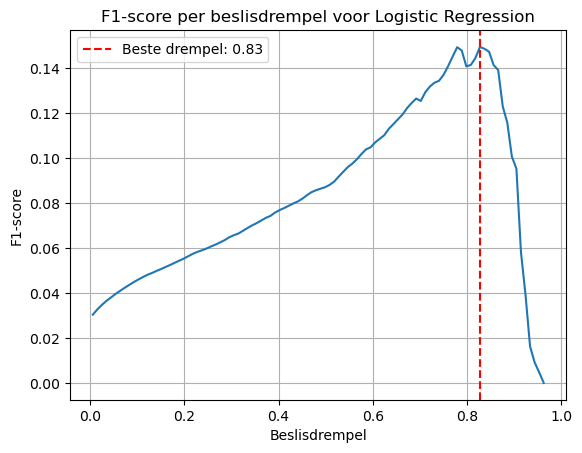

In [31]:
results = best_lr_model.cv_results_
best_threshold = best_lr_model.best_threshold_

plt.plot(results["thresholds"], results["scores"])
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Beste drempel: {round(best_threshold, 2)}")

plt.xlabel("Beslisdrempel")
plt.ylabel("F1-score")
plt.title("F1-score per beslisdrempel voor Logistic Regression")
plt.legend()
plt.grid()
plt.show()

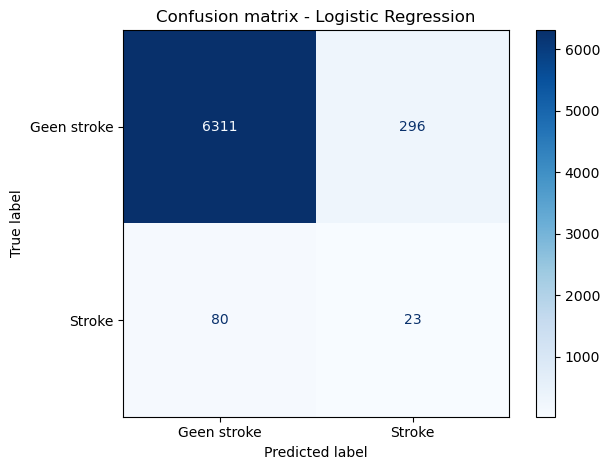

In [32]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    cmap="Blues",
)

plt.title("Confusion matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [33]:
submission_lr = maak_submission(
    best_lr_model, X, y, test, tests_ids,
    "../submission_lr_threshold_fixed_nieuw.csv",
)


Opgeslagen: ../submission_lr_threshold_fixed_nieuw.csv
Scoremethode: predict_proba
Gebruikte drempel: 0.827444
Aantal positieve voorspellingen: 440


### 3.3.4 Resultaten Logistic Regression

Met GridSearchCV hebben we L1- en L2-regularisatie, verschillende waarden voor `C` en twee samplingtechnieken vergeleken.

De beste instellingen volgens cross-validation zijn:

| Hyperparameter | Beste waarde |
|---|---|
| Regularisatie | L1 |
| C | 0,01 |
| Sampling | RandomOverSampler |
| Beslisdrempel | 0,8274 |

De gemiddelde CV-F1 is **0,1499**. Op de aparte validatieset behalen we een F1-score van **0,1090**, een precision van 0,0721 en een recall van 0,2233. De lage precision laat zien dat veel positieve voorspellingen fout-positief zijn.

De validatie F1 ligt duidelijk lager dan de CV-F1. Dit kan worden veroorzaakt door verschillen tussen de folds en de validatieset.

In dit experiment werd L1-regularisatie met een lage `C` geselecteerd. Hierdoor worden gewichten relatief sterk bestraft en kan het model minder relevante kenmerken minder zwaar laten meewegen.

**Kaggle:** de eerder ingediende Logistic Regression-versie behaalde een Public F1 van 0,09966.

## 3.4 SVM

### 3.4.1 Werking

Een support vector machine, kort voor SVM, wordt gebruikt om datapunten van verschillende klassen van elkaar te scheiden. Bij binaire classificatie probeert SVM een scheidingsvlak te vinden waarmee je de twee klassen zo goed mogelijk van elkaar worden gescheiden. Hierbij gebruikt hij dezelfde formule als bij LR.

$$
f(x) = w_1x_1 + w_2x_2 + \dots + w_nx_n + b
$$

Maar SVM probeert niet zomaar een scheidingslijn te vinden. Het doel is om de grootst mogelijke marge tussen twee klassen te vinden. De marge wordt hierbij bepaald door de lengte van de gewichtenvector
$$
\boxed{\text{marge} = \frac{2}{\lVert w \rVert}}
$$

$$
\lVert w \rVert = \sqrt{w_1^2 + w_2^2 + \dots + w_n^2}
$$

Een kleinere $\lVert w \rVert$ betekent dus een grotere marge. De datapunten die het dichtst bij het scheidingsvlak liggen noemen we de **support vectors**. Deze punten bepalen de positie van de scheidingslijn en de marge.

Je hebt 2 verschillende soorten marges, **hard en soft**. Bij een hard margin moeten alle datapunten correct aan hun kant van de marge liggen. Dit werkt alleen als de data perfect lineair scheidbaar is. Bij een soft margin mag een datapunt de marge overschrijden of verkeerd geclassificeerd worden. Dit wordt geregeld met een slackvariabele $\xi$:

$$
y_i(w^T x_i + b) \geq 1 - \xi_i
$$

De waarde van $\xi_i$ geeft aan waar een datapunt ligt:

- $\xi_i = 0$: het punt ligt goed, buiten of op de marge. Geen overtreding.
- $0 < \xi_i < 1$: het punt ligt binnen de marge, maar nog wel aan de goede kant van het hypervlak.
- $\xi_i = 1$: het punt ligt precies op het scheidingsvlak.
- $\xi_i > 1$: het punt ligt aan de verkeerde kant van het hypervlak en is dus fout geclassificeerd.

De parameter $C$ bepaalt hoe streng deze overtredingen worden bestraft. $C$ is daarmee ook onderdeel van de **regularisatie** van SVM.

- **Hoge $C$** → fouten zwaar bestraft → kleinere marge en minder fouten op de trainingsdata → meer kans op overfitting.
- **Lage $C$** → fouten minder zwaar bestraft → grotere marge en meer tolerantie voor fouten → meer kans op underfitting.

De optimalisatie bij soft-margin SVM kan worden geschreven als:

$$
\boxed{\min_{w,b,\xi} \; \frac{1}{2}\lVert w \rVert^2 + C \sum_{i=1}^{n} \xi_i}
$$

Hier probeert SVM dus twee dingen tegelijk te doen:

1. $\frac{1}{2}\lVert w \rVert^2$ zo klein mogelijk maken → **marge maximaliseren en regulariseren**
2. $C \sum \xi_i$ zo klein mogelijk maken → **fouten en marge-overtredingen beperken**

De eerste term werkt dus als regularisatie: het model wordt gestimuleerd om een zo groot mogelijke marge te kiezen in plaats van de trainingsdata volledig te willen passen.

### Hinge loss

De optimalisatie hierboven hangt samen met de **hinge loss**. Deze lossfunctie geeft aan hoeveel een datapunt de gewenste marge overschrijdt:

$$
\boxed{L = \max(0, 1-y_i f(x_i))}
$$

Hierbij gebruiken we in de formules $y_i=-1$ voor geen stroke en $y_i=+1$ voor stroke. In de dataset blijven de labels 0 en 1; scikit-learn verwerkt dit intern. $f(x_i)$ is de beslissingsscore, geen kans of voorspeld klasselabel.

Wanneer een datapunt correct en buiten de marge ligt, is de loss $0$. Ligt het datapunt binnen de marge of aan de verkeerde kant van het scheidingsvlak, dan is de loss groter dan $0$.

De hinge loss zorgt er dus voor dat SVM niet alleen probeert de datapunten correct te classificeren, maar ook probeert voldoende afstand tot het scheidingsvlak te behouden.


### 3.4.2 Berekening met data

We gebruiken drie echte rijen uit data/train.csv en alleen leeftijd en BMI:

| id | Leeftijd | BMI | Stroke | $y_i$ in de formule |
| --- | --- | --- | --- | --- |
| 52709 | 30 | 33,3 | 0 | −1 |
| 72295 | 75 | 48,0 | 0 | −1 |
| 13491 | 80 | 31,7 | 1 | +1 |

Om de berekening simpel te laten zien kiezen we zelf $w_1=0{,}1$, $w_2=-0{,}1$ en $b=-4$. Dit zijn **voorbeeldgewichten**, niet de gewichten van ons getrainde model. Alleen voor dit voorbeeld gebruiken we ongeschaalde waarden; de echte SVM gebruikt de schaalpipeline.

$$
f(x) = 0{,}1 \cdot \text{leeftijd} - 0{,}1 \cdot \text{BMI} - 4
$$

Voor patiënt 13491:

$$
f(x) = 0{,}1 \cdot 80 - 0{,}1 \cdot 31{,}7 - 4 = 0{,}83
$$

- De score is positief, dus met de standaardgrens 0 voorspellen we stroke.
- De echte klasse is $+1$, dus $y_i f(x_i)=0{,}83$.
- De hinge loss is $\max(0,1-0{,}83)=0{,}17$. Het punt is goed geclassificeerd, maar ligt nog binnen de marge.

Voor alle drie de patiënten krijgen we:

| id | $f(x_i)$ | $y_i f(x_i)$ | Hinge loss |
| --- | --- | --- | --- |
| 52709 | −4,33 | 4,33 | 0 |
| 72295 | −1,30 | 1,30 | 0 |
| 13491 | 0,83 | 0,83 | 0,17 |

De eerste twee patiënten liggen aan de goede kant en buiten de marge. Hun loss is daarom 0. In het echte model tunen we ook de beslisdrempel op F1; die hoeft dus niet 0 te zijn.

Bron: [scikit-learn developers, z.d.-u](https://scikit-learn.org/1.6/modules/svm.html). De patiëntwaarden komen uit onze eigen trainingsdata.


### 3.4.3 Kernels

Een kernel bepaalt hoe de SVM de data vergelijkt en maakt het mogelijk om niet lineare patronen te classificeren. Met de kernel trick kan SVM data als het ware naar een hogere dimensie brengen zonder deze transformatie daadwerkelijk uit te voeren. Hierdoor kan SVM ook complexe patronen scheiden zonder dat alle nieuwe dimensies daadwerkelijk berekend hoeven te worden. De kernels zijn:

#### Linear

Een lineare kernel zoekt een rechte lijn of een vlak om de klassem te scheiden. Dit valt te gebruiken als de data linear scheidbaar is.

#### Polynomal

De polynomiale kernel maakt de relatie tussen features complexer, waardoor een SVM een paraboolachtige of gebogen beslissingsgrens kan trekken. Dit valt te gebruiken als de data een gebogen structuur heeft.

#### RBF (Radial Basis Function)

RBF kan flexibele en complexe scheidingsgrenzen maken door ze in een soort groepen te verdelen waardoor je allemaal vlakken krijgt met klassen. Valt te gebruiken als de data niet linear is.

#### Sigmoid

De sigmoid kernel maakt een niet-lineaire scheidingsgrens en kan gebruikt worden wanneer de data niet lineair scheidbaar is.

In [34]:
# AI-bron: Claude, SVM-code op basis van LR en KNN (zie AI-referentielijst).
# https://claude.ai/share/e793cc47-1e24-4f48-8f86-6ba82efbbd7e

# Gebruikt de schaalstap uit onze scaled pipeline 
preprocessing = make_scaled_pipeline(SVC()).named_steps["preprocessing"]

svm_pipeline = ImbPipeline(steps=[
    ("preprocessing", preprocessing),                 # 1. features schalen
    ("sampler", RandomOverSampler(random_state=42)),  # 2. klassen in balans brengen
    ("model", SVC(cache_size=1000)),                  # 3. het SVM-model zelf
])

# 3 fold CV waarmee de beste beslisdrempel wordt gekozen
threshold_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Zoekt de beslisdrempel met de hoogste F1 score voor de SVM pipeline
svm_with_threshold = TunedThresholdClassifierCV(
    estimator=svm_pipeline,
    scoring="f1",
    cv=threshold_cv,
    store_cv_results=True
)

samplers = [
    RandomOverSampler(random_state=42),   # zorgt ervoor dat de minderheidsklasse (stroke) wordt bijkopieerd
    RandomUnderSampler(random_state=42),  # zorgt ervoor dat de meerderheidsklasse (geen stroke) wordt uitgedund
]

# Alle combinaties van instellingen die de gridsearch gaat uitproberen
svm_param_grid = [
    {
        "estimator__sampler": samplers,
        "estimator__model__kernel": ["linear"],           # rechte scheidingslijn
        "estimator__model__C": [0.01, 0.1, 1],            # regularisatie: klein = zachtere marge
    },
    {
        "estimator__sampler": samplers,
        "estimator__model__kernel": ["rbf"],              # flexibele, gebogen scheidingslijn
        "estimator__model__C": [0.1, 1, 10],
        "estimator__model__gamma": ["scale", 0.01, 0.1],  # hoe lokaal één datapunt invloed heeft
    },
    {
        "estimator__sampler": samplers,
        "estimator__model__kernel": ["poly"],             # polynomiale (paraboolachtige) scheidingslijn
        "estimator__model__degree": [2, 3],               # graad van het polynoom
        "estimator__model__C": [0.1, 1],
        "estimator__model__coef0": [1],
    },
    {
        "estimator__sampler": samplers,
        "estimator__model__kernel": ["sigmoid"],          # sigmoid-vormige scheidingslijn
        "estimator__model__C": [0.1, 1],
        "estimator__model__coef0": [0, 1],
    },
]

# Probeert elke combinatie van de grid en kiest de beste op basis van de F1 score
svm_threshold_search = GridSearchCV(
    estimator=svm_with_threshold,
    param_grid=svm_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)

svm_threshold_search.fit(X_train, y_train)

# Het model met de beste instellingen en threshold
best_svm_model = svm_threshold_search.best_estimator_

y_pred_svm = best_svm_model.predict(X_test)

toon_resultaten(svm_threshold_search)


Beste instellingen: {'estimator__model__C': 1, 'estimator__model__kernel': 'linear', 'estimator__sampler': RandomOverSampler(random_state=42)}
Beslisdrempel: 1.125456
CV-F1: 0.1567


Accuracy     0.9255
Precision    0.0803
Recall       0.3689
F1           0.1319
Name: Validatiescore, dtype: float64

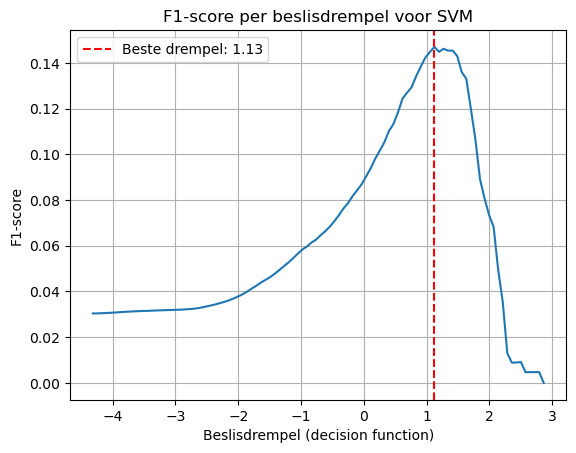

In [35]:
results = best_svm_model.cv_results_
best_threshold = best_svm_model.best_threshold_

plt.plot(results["thresholds"], results["scores"])
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Beste drempel: {round(best_threshold, 2)}")

plt.xlabel("Beslisdrempel (decision function)")
plt.ylabel("F1-score")
plt.title("F1-score per beslisdrempel voor SVM")
plt.legend()
plt.grid()
plt.show()

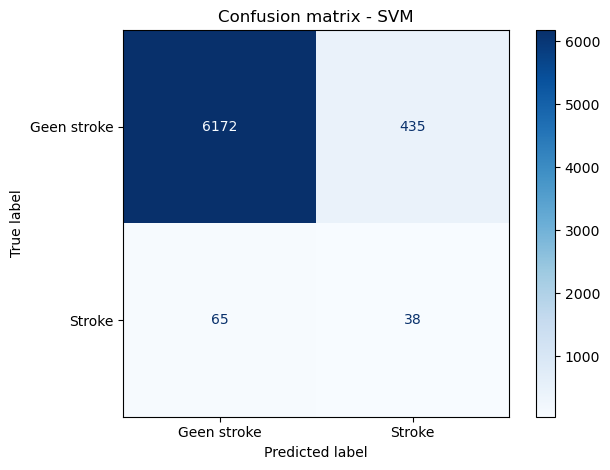

In [36]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    cmap="Blues",
)

plt.title("Confusion matrix - SVM")
plt.tight_layout()
plt.show()

In [37]:
submission_svm = maak_submission(
    best_svm_model, X, y, test, tests_ids,
    "../submission_svm_threshold_fixed_nieuw.csv",
)


Opgeslagen: ../submission_svm_threshold_fixed_nieuw.csv
Scoremethode: decision_function
Gebruikte drempel: 1.125456
Aantal positieve voorspellingen: 624


### 3.4.4 Resultaten SVM

De beste instellingen volgens cross-validation zijn:

| Hyperparameter | Beste waarde |
|---|---|
| Kernel | Linear |
| C | 1 |
| Sampling | RandomOverSampler |
| Beslisdrempel | 1,1255 |

Het model behaalt een gemiddelde CV-F1 van **0,1567**. Hiermee heeft SVM de hoogste gemiddelde CV-F1 van onze afzonderlijke modellen.

Op de aparte validatieset behalen we:

| Metric | Score |
|---|---:|
| Accuracy | 0,9255 |
| Precision | 0,0803 |
| Recall | 0,3689 |
| F1-score | 0,1319 |

Het model herkent 36,89% van de werkelijke strokegevallen, maar de precision van 8,03% laat zien dat veel positieve voorspellingen onjuist zijn.

Op Kaggle behaalde de SVM met de oorspronkelijke beslisdrempel een Public F1 van **0,09470**. Bij een aanvullend experiment hebben we de beslisdrempel na training op de volledige dataset opnieuw geoptimaliseerd. Daarmee steeg de Public F1 licht naar **0,09811**.

Ondanks de relatief hoge lokale F1-scores presteert SVM op Kaggle minder goed dan KNN. Een hogere cross-validation-score garandeert dus niet dat het model ook op nieuwe testdata beter presteert.

## 3.5 Decision Tree

Een **Decision Tree** is een model dat de data stap voor stap opsplitst op basis van kenmerken. Bij iedere splitsing wordt gekeken welke feature en welke grens de data het beste in verschillende klassen verdeelt. Uiteindelijk komt ieder datapunt in een blad terecht waarin de voorspelde klasse staat.

### Werking

Een Decision Tree begint bij de **root**. Vanuit deze root worden steeds nieuwe splitsingen gemaakt. Bijvoorbeeld: *is de leeftijd groter dan 60?* Afhankelijk van het antwoord gaat het datapunt naar een volgende tak. Dit gaat door totdat het datapunt een **leaf** bereikt. De klasse van deze leaf is de voorspelling van het model.

### Criteria voor splitsingen

Om te bepalen welke splitsing het beste is, kan een Decision Tree verschillende criteria gebruiken. De belangrijkste zijn **Gini impurity** en **entropy**.

**Gini impurity** meet hoe gemengd de klassen in een node zijn. Een waarde van 0 betekent dat alle datapunten tot dezelfde klasse behoren. De formule is:

$$
Gini = 1 - \sum_{i=1}^{n} p_i^2
$$

waarbij $p_i$ de verhouding van klasse $i$ in de node is. De boom kiest de splitsing die de Gini impurity het meest verlaagt.

**Entropy** meet eveneens hoe gemengd de klassen zijn:

$$
Entropy = -\sum_{i=1}^{n} p_i \log_2(p_i)
$$

Een lagere entropy betekent dat de klassen beter gescheiden zijn. De boom kiest dus een splitsing die de impurity zo veel mogelijk vermindert.

### Hyperparameters

Met **hyperparameter tuning** wordt gezocht naar de instellingen waarbij de Decision Tree de beste **F1-score** behaalt. Belangrijke hyperparameters zijn onder andere:

- **criterion**: bepaalt of Gini of entropy wordt gebruikt.
- **max_depth**: bepaalt hoe diep de boom maximaal mag worden.
- **min_samples_split**: bepaalt hoeveel datapunten minimaal nodig zijn om een node verder te splitsen.
- **min_samples_leaf**: bepaalt hoeveel datapunten minimaal in een leaf moeten zitten.

De beste combinatie van deze hyperparameters wordt bepaald met cross-validation en wordt vervolgens gebruikt voor het uiteindelijke model.

### Pruning

**Pruning** betekent dat de Decision Tree wordt beperkt of kleiner wordt gemaakt om te voorkomen dat het model de trainingsdata te goed leert.

Er zijn twee vormen van pruning:

- **Pre-pruning**: de boom wordt tijdens het bouwen beperkt. Dit kan bijvoorbeeld met `max_depth`, `min_samples_split` en `min_samples_leaf`.
- **Post-pruning**: eerst wordt een volledige boom gebouwd en daarna worden onnodige takken verwijderd. Dit kan bijvoorbeeld met `ccp_alpha`.

Pruning helpt tegen **overfitting**. Zonder voldoende pruning kan een boom te diep worden en zelfs kleine details en ruis uit de trainingsdata leren. Hierdoor presteert het model goed op de trainingsdata, maar slechter op nieuwe data. Te veel pruning kan juist **underfitting** veroorzaken, omdat de boom dan te simpel wordt en belangrijke patronen niet meer leert.

Het doel is daarom een balans te vinden waarbij de boom complex genoeg is om de data goed te leren, maar niet zo complex dat hij de trainingsdata uit het hoofd leert.

Bron: ([scikit-learn developers, z.d.-s](https://scikit-learn.org/stable/modules/tree.html)).

In [38]:
# Gebruikt de schaalstap uit onze scaled pipeline 
preprocessing = make_scaled_pipeline(DecisionTreeClassifier()).named_steps["preprocessing"]

tree_pipeline = ImbPipeline(steps=[
    ("preprocessing", preprocessing),                          # 1. features voorbereiden
    ("sampler", RandomOverSampler(random_state=42)),           # 2. klassen in balans brengen
    ("model", DecisionTreeClassifier(random_state=42)),        # 3. de decision tree zelf
])

# 3 fold CV waarmee de beste beslisdrempel wordt gekozen
threshold_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Zoekt de beslisdrempel met de hoogste F1 score voor de tree pipeline
tree_with_threshold = TunedThresholdClassifierCV(
    estimator=tree_pipeline,
    scoring="f1",
    cv=threshold_cv,
    store_cv_results=True
)

samplers = [
    RandomOverSampler(random_state=42),   # zorgt ervoor dat de minderheidsklasse (stroke) wordt bijkopieerd
    RandomUnderSampler(random_state=42),  # zorgt ervoor dat de meerderheidsklasse (geen stroke) wordt uitgedund
]

# Alle combinaties van instellingen die de gridsearch gaat uitproberen
tree_param_grid = {
    "estimator__sampler": samplers,
    "estimator__model__criterion": ["gini", "entropy"],      # manier om de beste splitsing te kiezen
    "estimator__model__max_depth": [3, 5, 7, 10, None],      # hoe diep de boom mag worden: dieper = complexer
    "estimator__model__min_samples_leaf": [1, 5, 20, 50],    # minimaal aantal punten per blad: hoger = minder overfitting
    "estimator__model__ccp_alpha": [0.0, 0.001, 0.01],       # snoeien: hoger = takken die weinig toevoegen worden weggehaald
}

# Probeert elke combinatie van de grid en kiest de beste op basis van de F1 score
tree_threshold_search = GridSearchCV(
    estimator=tree_with_threshold,
    param_grid=tree_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)

tree_threshold_search.fit(X_train, y_train)

# Het model met de beste instellingen en threshold
best_tree_model = tree_threshold_search.best_estimator_

y_pred_tree = best_tree_model.predict(X_test)

toon_resultaten(tree_threshold_search)


Beste instellingen: {'estimator__model__ccp_alpha': 0.0, 'estimator__model__criterion': 'gini', 'estimator__model__max_depth': 5, 'estimator__model__min_samples_leaf': 1, 'estimator__sampler': RandomOverSampler(random_state=42)}
Beslisdrempel: 0.858586
CV-F1: 0.152


Accuracy     0.9584
Precision    0.0728
Recall       0.1456
F1           0.0971
Name: Validatiescore, dtype: float64

age                            0.859934
bmi                            0.061901
avg_glucose_level              0.057286
hypertension                   0.011087
work_type_Private              0.006922
work_type_Self-employed        0.001313
smoking_status_never smoked    0.001232
ever_married_Yes               0.000327
gender_Other                   0.000000
heart_disease                  0.000000
dtype: float64


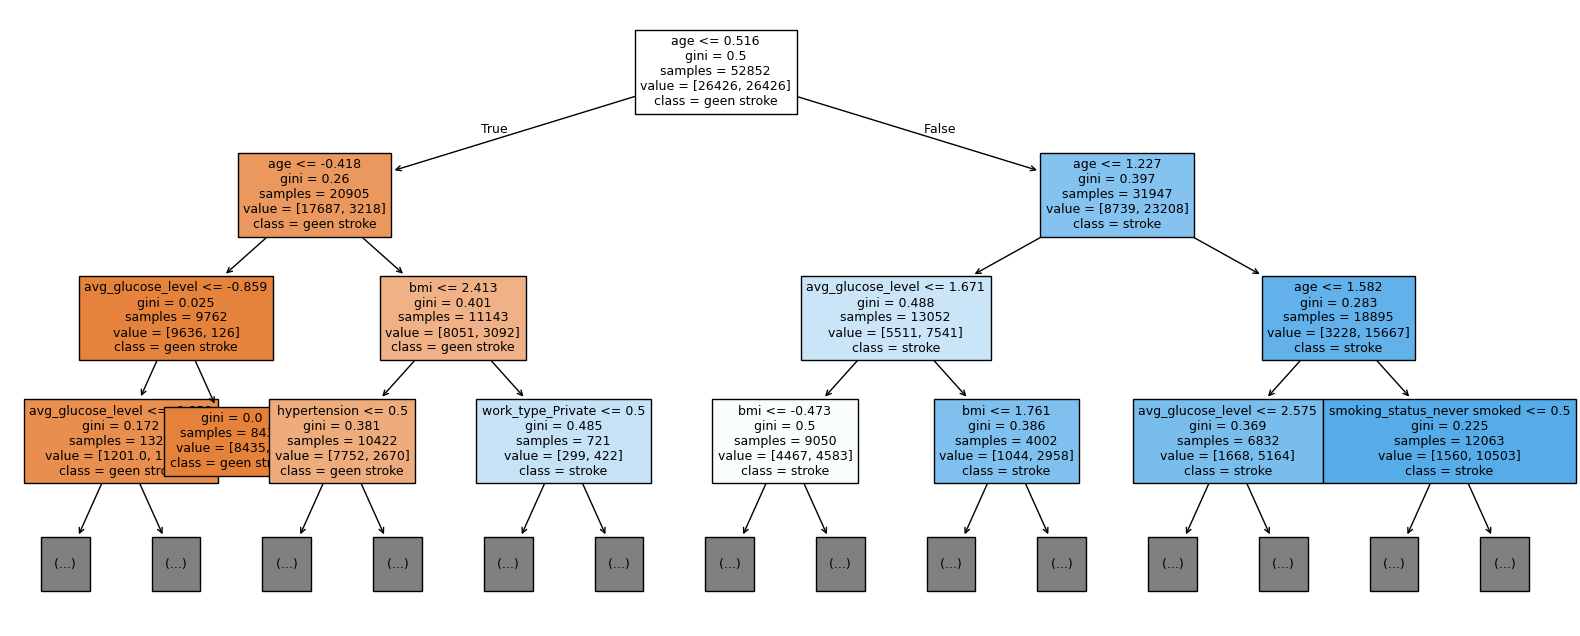

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

fitted_pipeline = best_tree_model.estimator_
tree_model = fitted_pipeline.named_steps["model"]
feature_names = fitted_pipeline.named_steps["preprocessing"].get_feature_names_out()

# Welke features de boom het meest gebruikt
importances = pd.Series(tree_model.feature_importances_, index=feature_names).sort_values(ascending=False)
print(importances.head(10))

# De bovenste lagen van de boom visualiseren
plt.figure(figsize=(20, 8))
plot_tree(tree_model, feature_names=feature_names, class_names=["geen stroke", "stroke"],
          max_depth=3, filled=True, fontsize=9)
plt.show()

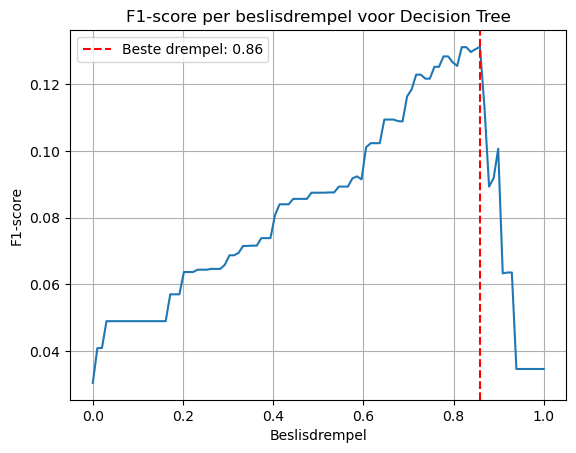

In [40]:
results = best_tree_model.cv_results_
best_threshold = best_tree_model.best_threshold_

plt.plot(results["thresholds"], results["scores"])
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Beste drempel: {round(best_threshold, 2)}")

plt.xlabel("Beslisdrempel")
plt.ylabel("F1-score")
plt.title("F1-score per beslisdrempel voor Decision Tree")
plt.legend()
plt.grid()
plt.show()

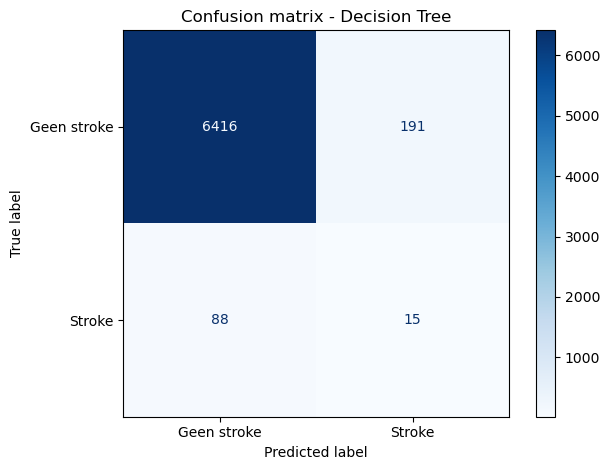

In [41]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tree,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    cmap="Blues",
)

plt.title("Confusion matrix - Decision Tree")
plt.tight_layout()
plt.show()

In [59]:
submission_tree = maak_submission(
    best_tree_model, X, y, test, tests_ids,
    "../submission_tree_1.csv",
)


Opgeslagen: ../submission_tree_1.csv
Scoremethode: predict_proba
Gebruikte drempel: 0.858586
Aantal positieve voorspellingen: 327


### 3.5.1 Resultaten Decision Tree

De beste instellingen volgens cross-validation zijn:

| Hyperparameter | Beste waarde |
|---|---|
| Criterion | Gini |
| Max depth | 5 |
| Min samples leaf | 1 |
| ccp_alpha | 0 |
| Sampling | RandomOverSampler |
| Beslisdrempel | 0,8586 |

De Decision Tree behaalt een gemiddelde CV-F1 van **0,1520** en een validatie-F1 van **0,0971**.

De precision is 0,0728 en de recall is 0,1456. Het model herkent daarmee slechts ongeveer 14,56% van de werkelijke strokegevallen.

**Pruning**

De beste configuratie gebruikt `max_depth=5`. Dit is een vorm van pre-pruning: tijdens het bouwen wordt de maximale diepte beperkt, zodat de boom niet onbeperkt kan doorgroeien.

De gekozen waarde `ccp_alpha=0` betekent dat er bij deze configuratie geen extra cost-complexity post-pruning wordt toegepast.

De beperkte diepte kan helpen om overfitting te voorkomen. Een te sterke beperking kan echter leiden tot underfitting. Met cross-validation hebben we onderzocht welke balans binnen onze geteste instellingen de hoogste F1-score oplevert.

Een eerdere Decision Tree-submission (`submission_tree_1.csv`) behaalde een Kaggle Public F1 van 0,07272. Omdat dit niet automatisch dezelfde configuratie is als de huidige getunede boom, moeten we die resultaten onderscheiden.

## 3.6 Ensembles

Een ensemble combineert meerdere modellen om één uiteindelijke voorspelling te maken. Het doel is om de sterke punten van verschillende modellen te benutten en de invloed van afzonderlijke fouten te verminderen.

In dit hoofdstuk vergelijken we Random Forest, Gradient Boosted Decision Trees (GBDT) en XGBoost.

### Bagging en boosting

Bij bagging (Bootstrap Aggregation) worden meerdere modellen getraind op verschillende steekproeven van de trainingsdata. De modellen zijn onafhankelijk van elkaar en kunnen daardoor parallel worden getraind. Random Forest gebruikt deze techniek.

Bij boosting worden modellen opeenvolgend getraind. Iedere nieuwe boom bouwt voort op de eerdere bomen en probeert de voorspellingen verder te verbeteren. GBDT en XGBoost gebruiken boosting.

Het belangrijkste verschil is dat bagging de modellen grotendeels onafhankelijk traint, terwijl boosting afhankelijk is van eerdere modelstappen.

### Sequential en parallel

Random Forest kan meerdere bomen parallel trainen omdat deze onafhankelijk van elkaar worden gebouwd.

GBDT en XGBoost trainen de opeenvolgende boostingrondes sequential, omdat iedere ronde voortbouwt op de vorige.

Voor alle drie de ensembles passen we cross-validation en hyperparametertuning toe. Ook onderzoeken we technieken om met onze ongebalanceerde dataset om te gaan.

### 3.6.1 Random Forest

Een **Random Forest** is een ensemblemodel dat bestaat uit meerdere **Decision Trees**. In plaats van één Decision Tree te gebruiken, worden meerdere bomen getraind en worden hun voorspellingen gecombineerd. Hierdoor is het model minder afhankelijk van één enkele boom en kan het beter generaliseren.

#### Werking

Bij een Random Forest worden meerdere Decision Trees gemaakt. Iedere boom krijgt een willekeurige steekproef van de trainingsdata en gebruikt daarnaast bij iedere splitsing slechts een willekeurige selectie van de beschikbare features.

De voorspellingen van alle bomen worden vervolgens gecombineerd. Bij classificatie wordt meestal gebruikgemaakt van **majority voting**. De klasse die door de meeste bomen wordt voorspeld, wordt de uiteindelijke voorspelling van het Random Forest.

#### Bagging en Bootstrap Aggregation

Random Forest maakt gebruik van **bagging**, wat staat voor **Bootstrap Aggregation**.

Bij bootstrap sampling wordt voor iedere Decision Tree een nieuwe trainingsset gemaakt door willekeurig datapunten uit de originele dataset te trekken. Hierbij mogen datapunten meerdere keren worden gekozen. Hierdoor krijgt iedere boom een iets andere trainingsset.

De bomen worden vervolgens afzonderlijk van elkaar getraind. Omdat de bomen onafhankelijk van elkaar zijn, kunnen ze **parallel** worden getraind. Dit maakt Random Forest relatief efficiënt wanneer er veel bomen moeten worden getraind.

Door de voorspellingen van meerdere verschillende bomen te combineren, wordt de invloed van individuele fouten kleiner. Hierdoor heeft Random Forest meestal minder last van overfitting dan één grote Decision Tree.

Bronnen:

- ([scikit-learn developers, z.d.-t](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees))
- ([scikit-learn developers, z.d.-g](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html))

In [43]:
# Gebruikt de schaalstap uit onze scaled pipeline 
preprocessing = make_scaled_pipeline(RandomForestClassifier()).named_steps["preprocessing"]

rf_pipeline = ImbPipeline(steps=[
    ("preprocessing", preprocessing),                     # 1. features voorbewerken
    ("sampler", RandomOverSampler(random_state=42)),      # 2. klassen in balans brengen
    ("model", RandomForestClassifier(random_state=42,     # 3. het Random Forest-model zelf
                                     n_jobs=1)),
])

# 3 fold CV waarmee de beste beslisdrempel wordt gekozen
threshold_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Zoekt de beslisdrempel met de hoogste F1 score voor de RF pipeline
rf_with_threshold = TunedThresholdClassifierCV(
    estimator=rf_pipeline,
    scoring="f1",
    cv=threshold_cv,
    store_cv_results=True
)

samplers = [
    RandomOverSampler(random_state=42),   # minderheidsklasse (stroke) wordt bijkopieerd
    RandomUnderSampler(random_state=42),  # meerderheidsklasse (geen stroke) wordt uitgedund
]

# Alle combinaties van instellingen die de gridsearch gaat uitproberen
rf_param_grid = [
    {
        "estimator__sampler": samplers,
        "estimator__model__n_estimators": [300],           # aantal bomen
        "estimator__model__max_depth": [None, 5, 10],      # max diepte per boom: klein = simpeler model
        "estimator__model__min_samples_leaf": [1, 5, 10],  # min. punten per blad: hoger = minder overfitting
        "estimator__model__max_features": ["sqrt", 0.5],   # aantal features per split: meer variatie tussen bomen
    },
    {
        "estimator__sampler": ["passthrough"],             # geen sampling
        "estimator__model__class_weight": ["balanced", "balanced_subsample"],  # zwaarder gewicht voor stroke
        "estimator__model__n_estimators": [300],
        "estimator__model__max_depth": [None, 5, 10],
        "estimator__model__min_samples_leaf": [1, 5, 10],
        "estimator__model__max_features": ["sqrt", 0.5],
    },
]

# Probeert elke combinatie van de grid en kiest de beste op basis van de F1 score
rf_threshold_search = GridSearchCV(
    estimator=rf_with_threshold,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)

rf_threshold_search.fit(X_train, y_train)

# Het model met de beste instellingen en threshold
best_rf_model = rf_threshold_search.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)

toon_resultaten(rf_threshold_search)


Beste instellingen: {'estimator__model__class_weight': 'balanced_subsample', 'estimator__model__max_depth': 5, 'estimator__model__max_features': 0.5, 'estimator__model__min_samples_leaf': 1, 'estimator__model__n_estimators': 300, 'estimator__sampler': 'passthrough'}
Beslisdrempel: 0.730032
CV-F1: 0.1434


Accuracy     0.9140
Precision    0.0659
Recall       0.3495
F1           0.1109
Name: Validatiescore, dtype: float64

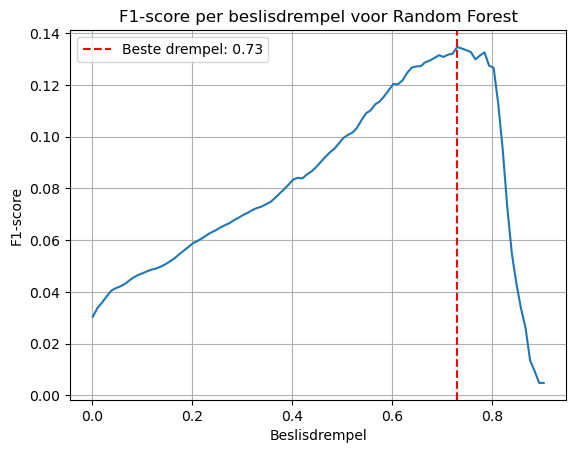

In [44]:
results = best_rf_model.cv_results_
best_threshold = best_rf_model.best_threshold_

plt.plot(results["thresholds"], results["scores"])
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Beste drempel: {round(best_threshold, 2)}")

plt.xlabel("Beslisdrempel")
plt.ylabel("F1-score")
plt.title("F1-score per beslisdrempel voor Random Forest")
plt.legend()
plt.grid()
plt.show()

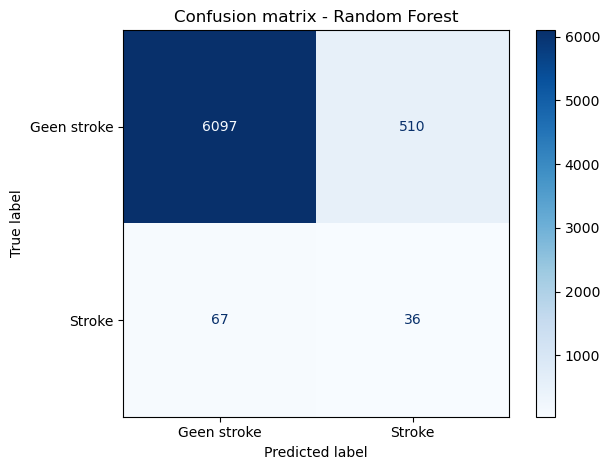

In [45]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    cmap="Blues",
)

plt.title("Confusion matrix - Random Forest")
plt.tight_layout()
plt.show()

In [46]:
submission_rf = maak_submission(
    best_rf_model,
    X,
    y,
    test,
    tests_ids,
    "../submission_rf.csv",
)

Opgeslagen: ../submission_rf.csv
Scoremethode: predict_proba
Gebruikte drempel: 0.730032
Aantal positieve voorspellingen: 817


#### Resultaten Random Forest

Met GridSearchCV hebben we verschillende instellingen geprobeerd voor het aantal bomen, de maximale boomdiepte, het minimumaantal voorbeelden per blad en het aantal kenmerken dat per splitsing wordt overwogen.

Daarnaast hebben we samplingtechnieken en class weights onderzocht om rekening te houden met de ongebalanceerde dataset.

De beste instellingen zijn:

| Hyperparameter | Beste waarde |
|---|---|
| n_estimators | 300 |
| max_depth | 5 |
| min_samples_leaf | 1 |
| max_features | 0,5 |
| class_weight | balanced_subsample |
| Sampling | Geen aanvullende resampling |
| Beslisdrempel | 0,7300 |

De gemiddelde CV-F1 is **0,1434**. Op de validatieset behalen we een F1-score van **0,1109**, een precision van 0,0659 en een recall van 0,3495.

De GridSearchCV heeft gekozen voor `balanced_subsample` zonder aanvullende sampling. Bij deze methode worden de klassegewichten per bootstrap-steekproef bepaald. Hierdoor krijgt de minderheidsklasse extra invloed tijdens de training.

Het model behaalde op Kaggle een Public F1 van **0,08370** met onze `submission_rf.csv`.

Ondanks het combineren van 300 beslisbomen is Random Forest daarmee niet ons beste model.

### 3.6.2 Gradient Boosted Decision Trees

Een **Gradient Boosted Decision Trees-model (GBDT)** combineert meerdere kleine bomen. Iedere nieuwe boom probeert de fouten van de vorige bomen te verbeteren.

#### Werking en boosting

- We beginnen met een eenvoudige voorspelling.
- Daarna trainen we steeds een nieuwe boom op de richting waarin de loss kleiner wordt: de **negatieve gradient**.
- De bomen geven correcties op een score. We tellen deze op en zetten de eindscore om naar een kans op stroke.
- Dit is **boosting**, geen bagging. Bij bagging worden bomen onafhankelijk getraind; bij boosting bouwen ze op elkaar voort.

De score wordt iedere ronde aangepast:

$$
F_m(x) = F_{m-1}(x) + \eta h_m(x)
$$

Hier is $F_{m-1}(x)$ de vorige score, $h_m(x)$ de correctie van de nieuwe boom en $\eta$ de learning rate. Bijvoorbeeld: bij een vorige score van 0,2, een correctie van 0,4 en een learning rate van 0,1 wordt de nieuwe score $0,2 + 0,1 \times 0,4 = 0,24$. Dit is een voorbeeldscore, geen getrainde voorspelling of kans.

Bron: [scikit-learn developers, z.d.-w](https://scikit-learn.org/1.6/modules/ensemble.html#gradient-tree-boosting).

#### Sequential en trainingstijd

- De bomen worden **sequential** getraind: een boom heeft de uitkomst van de vorige bomen nodig.
- Random Forest kan de bomen juist **parallel** trainen. GBDT kan daardoor relatief veel trainingstijd kosten.
- Wel kunnen de CV-runs en instellingen van de gridsearch parallel worden getest. De werkelijke tijd hangt ook af van de data, instellingen en computer; daarom meten we de totale zoektijd.

#### Onze keuzes

- We gebruiken `GradientBoostingClassifier` met `log_loss`: geschikt voor binaire classificatie met kansuitvoer.
- We vergelijken **oversampling** en **undersampling**. Oversampling kopieert stroke-rijen, maar maakt geen nieuwe informatie. Undersampling verwijdert geen-stroke-rijen, maar kan informatie verliezen. Beide gebeuren alleen binnen de trainingsfold.
- We vergelijken 100 bomen met learning rate 0,1 en 200 bomen met learning rate 0,05. Een kleinere stap krijgt zo meer bomen. Dit zijn twee gekozen combinaties, niet alle mogelijke instellingen.
- We testen `max_depth` 2 en 3 en houden minimaal 5 rijen per blad. Kleine bomen beperken de complexiteit; te kleine bomen kunnen ook underfitten.
- We behouden de bestaande preprocessing voor dezelfde pipeline-opbouw. Schalen is voor deze bomen niet nodig.
- Zoals bij de andere modellen kiezen we instellingen met **5-fold CV-F1**. De drempel kiezen we met **3-fold CV binnen de training**, niet op de validatieset.
- De grid heeft 8 combinaties. We houden hem klein omdat iedere combinatie meerdere trainingen nodig heeft. `random_state=42` maakt de runs herhaalbaar.

Bron: [scikit-learn developers, z.d.-x](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html).

AI-ondersteuning: OpenAI Codex, 8 oktober 2026, prompt 28 uit de [main codex chat](https://chatgpt.com/s/cx_6aca1353637c8191af4b69d39af6d148). Zie de AI-referentielijst.

In [47]:
# Prompt 28: GBDT en XGBoost (OpenAI Codex).
# AI-ondersteuning, 8 oktober 2026; zie de AI-referentielijst.
from time import perf_counter
from sklearn.ensemble import GradientBoostingClassifier

# Dezelfde preprocessing als bij de andere modellen.
gbdt_preprocessing = make_scaled_pipeline(
    GradientBoostingClassifier()
).named_steps["preprocessing"]

gbdt_pipeline = ImbPipeline(steps=[
    ("preprocessing", gbdt_preprocessing),
    ("sampler", RandomOverSampler(random_state=42)),
    ("model", GradientBoostingClassifier(
        loss="log_loss",
        min_samples_leaf=5,
        random_state=42,
    )),
])

# Drempeltuning gebeurt alleen binnen de trainingsdata.
gbdt_threshold_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42
)
gbdt_with_threshold = TunedThresholdClassifierCV(
    estimator=gbdt_pipeline,
    scoring="f1",
    response_method="predict_proba",
    cv=gbdt_threshold_cv,
    store_cv_results=True,
)

gbdt_samplers = [
    RandomOverSampler(random_state=42),
    RandomUnderSampler(random_state=42),
]

# Kleinere learning rate koppelen we aan meer bomen.
gbdt_param_grid = [
    {
        "estimator__sampler": gbdt_samplers,
        "estimator__model__n_estimators": [aantal_bomen],
        "estimator__model__learning_rate": [learning_rate],
        "estimator__model__max_depth": [2, 3],
    }
    for aantal_bomen, learning_rate in [(100, 0.1), (200, 0.05)]
]

gbdt_threshold_search = GridSearchCV(
    estimator=gbdt_with_threshold,
    param_grid=gbdt_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    error_score="raise",
)

gbdt_start = perf_counter()
gbdt_threshold_search.fit(X_train, y_train)
gbdt_zoektijd = perf_counter() - gbdt_start

best_gbdt_model = gbdt_threshold_search.best_estimator_
y_pred_gbdt = best_gbdt_model.predict(X_test)

toon_resultaten(gbdt_threshold_search)
print("Totale zoektijd (minuten):", round(gbdt_zoektijd / 60, 2))

# Beste CV-resultaat per samplingtechniek, inclusief spreiding.
gbdt_vergelijking = pd.DataFrame(gbdt_threshold_search.cv_results_)
gbdt_vergelijking["Sampling"] = [
    type(sampler).__name__
    for sampler in gbdt_vergelijking["param_estimator__sampler"]
]
gbdt_beste_per_sampler = (
    gbdt_vergelijking.sort_values("mean_test_score", ascending=False)
    .drop_duplicates("Sampling")
)
display(
    gbdt_beste_per_sampler[
        ["Sampling", "mean_test_score", "std_test_score", "params"]
    ].rename(columns={
        "mean_test_score": "CV-F1",
        "std_test_score": "Spreiding CV-F1",
    })
)


Beste instellingen: {'estimator__model__learning_rate': 0.1, 'estimator__model__max_depth': 2, 'estimator__model__n_estimators': 100, 'estimator__sampler': RandomOverSampler(random_state=42)}
Beslisdrempel: 0.766944
CV-F1: 0.1437


Accuracy     0.9210
Precision    0.0789
Recall       0.3883
F1           0.1311
Name: Validatiescore, dtype: float64

Totale zoektijd (minuten): 0.63


,Sampling,CV-F1,Spreiding CV-F1,params
0,RandomOverSampler,0.143672,0.019384,"{'estimator__model__learning_rate': 0.1, 'esti..."
5,RandomUnderSampler,0.141959,0.016308,"{'estimator__model__learning_rate': 0.05, 'est..."


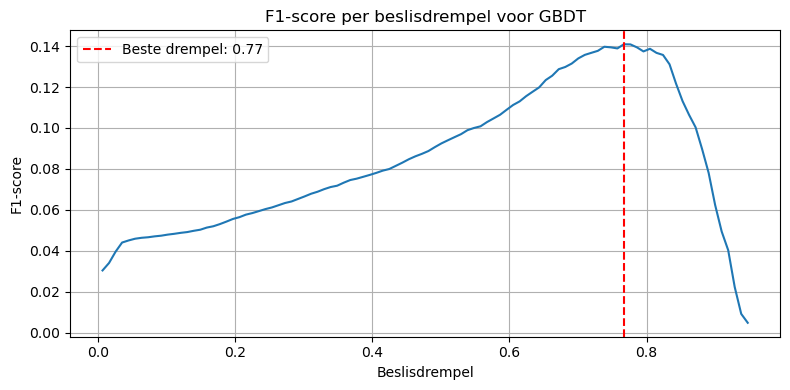

In [48]:
results = best_gbdt_model.cv_results_
best_threshold = best_gbdt_model.best_threshold_

plt.figure(figsize=(8, 4))
plt.plot(results["thresholds"], results["scores"])
plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Beste drempel: {best_threshold:.2f}",
)
plt.xlabel("Beslisdrempel")
plt.ylabel("F1-score")
plt.title("F1-score per beslisdrempel voor GBDT")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


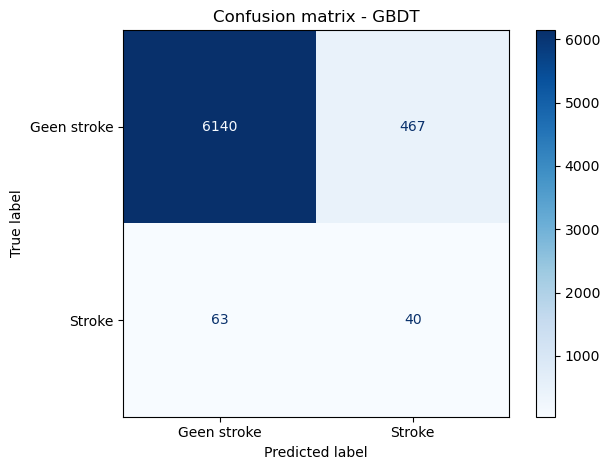

In [49]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_gbdt,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    values_format="d",
    cmap="Blues",
)
plt.title("Confusion matrix - GBDT")
plt.tight_layout()
plt.show()


#### Resultaten GBDT

De beste instellingen volgens cross-validation zijn:

| Hyperparameter | Beste waarde |
|---|---|
| n_estimators | 100 |
| learning_rate | 0,1 |
| max_depth | 2 |
| min_samples_leaf | 5 |
| Sampling | RandomOverSampler |
| Beslisdrempel | 0,7669 |

De gemiddelde CV-F1 is **0,1437**. Op de validatieset behalen we een F1-score van **0,1311**, een precision van 0,0789 en een recall van 0,3883.

We hebben twee technieken voor klasse-onbalans vergeleken:

| Samplingtechniek | Beste gemiddelde CV-F1 |
|---|---:|
| RandomOverSampler | **0,1437** |
| RandomUnderSampler | 0,1420 |

RandomOverSampler behaalde binnen de geteste configuraties de hoogste gemiddelde CV-F1. Het verschil is wel klein, waardoor we niet kunnen concluderen dat oversampling in alle situaties beter werkt.

Onze GBDT-submission behaalde een Kaggle Public F1 van **0,09882**.

### 3.6.3 XGBoost

**XGBoost** staat voor Extreme Gradient Boosting. Het gebruikt ook bomen die elkaar verbeteren, maar heeft extra regularisatie en een efficiënte manier om splitsingen te zoeken.

#### Werking en regularisatie

- Net als bij GBDT voegen we steeds een boom toe aan de bestaande score. De eindscore wordt omgezet naar een kans op stroke.
- XGBoost gebruikt zowel de gradient als de verandering van die gradient om de volgende correctie te bepalen.
- Het model kijkt niet alleen naar de loss, maar geeft ook een straf voor complexe bomen en grote bladscores. Dit helpt tegen overfitting.
- `reg_lambda` bepaalt de L2-straf op de bladscores. Een hogere waarde maakt grote correcties duurder.

De te minimaliseren functie is:

$$
\text{doelfunctie} = \sum_i L(y_i, p_i) + \sum_m \Omega(h_m)
$$

$L$ is de loss van de voorspelling en $\Omega$ is de straf op de complexiteit van een boom. We willen dus goede voorspellingen, zonder een onnodig ingewikkeld model.

Bron: [XGBoost developers, z.d.-a](https://xgboost.readthedocs.io/en/release_3.0.0/tutorials/model.html).

#### Sequential en parallel

- De boostingrondes blijven **sequential**, omdat iedere nieuwe boom de eerdere voorspellingen gebruikt.
- Binnen het bouwen van een boom kan XGBoost wel werk **parallel** uitvoeren.
- We gebruiken `tree_method='hist'`. Kenmerkwaarden worden in bins verdeeld om minder mogelijke splitsingen te hoeven beoordelen.
- XGBoost kan hierdoor sneller zijn dan de gewone GBDT-implementatie, maar dat is niet gegarandeerd. We meten beide zoektijden; hun grids hebben niet evenveel combinaties.
- We zetten het model op `n_jobs=1` en de gridsearch op `n_jobs=-1`. Zo gebruiken we parallelle CV-runs zonder iedere run ook alle processorkernen te laten gebruiken.

Bronnen: [XGBoost developers, z.d.-b](https://xgboost.readthedocs.io/en/release_3.0.0/parameter.html) en [XGBoost developers, z.d.-c](https://xgboost.readthedocs.io/en/release_3.0.0/python/sklearn_estimator.html).

#### Onze keuzes

- `objective='binary:logistic'` geeft kansen voor onze twee klassen. `eval_metric='logloss'` past bij deze loss; de gridsearch kiest de winnaar nog steeds op **F1**, niet op logloss.
- We vergelijken dezelfde **over- en undersampling** als bij GBDT. Extra gewicht voor stroke zetten we niet tegelijk aan; anders compenseren we de onbalans dubbel.
- We gebruiken dezelfde twee combinaties van bomen en learning rate en dezelfde dieptes 2 en 3. Daarnaast vergelijken we `reg_lambda` 1 en 5: standaard versus sterkere regularisatie.
- Andere instellingen blijven op hun standaardwaarde. Zo heeft de grid 16 combinaties en houden we de rekentijd beperkt.
- Preprocessing, 5-fold CV, interne 3-fold drempeltuning en de aparte validatieset blijven gelijk aan de andere modellen.
- We gebruiken geen early stopping op onze validatieset: die houden we buiten de modelselectie.


AI-ondersteuning: OpenAI Codex, 8 oktober 2026, prompts 28 en 30 uit de [main codex chat](https://chatgpt.com/s/cx_6aca1353637c8191af4b69d39af6d148). Zie de AI-referentielijst.

In [50]:
# Prompts 28 en 30: GBDT en XGBoost, XGBoost aanvullen (OpenAI Codex).
# AI-ondersteuning, 8 oktober 2026; zie de AI-referentielijst.
from time import perf_counter
# Alleen als XGBoost ontbreekt: %pip install xgboost==3.0.5
from xgboost import XGBClassifier

# Dezelfde preprocessing als bij de andere modellen.
xgb_preprocessing = make_scaled_pipeline(
    XGBClassifier()
).named_steps["preprocessing"]

xgb_pipeline = ImbPipeline(steps=[
    ("preprocessing", xgb_preprocessing),
    ("sampler", RandomOverSampler(random_state=42)),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=1,
        random_state=42,
    )),
])

# Drempeltuning gebeurt alleen binnen de trainingsdata.
xgb_threshold_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42
)
xgb_with_threshold = TunedThresholdClassifierCV(
    estimator=xgb_pipeline,
    scoring="f1",
    response_method="predict_proba",
    cv=xgb_threshold_cv,
    store_cv_results=True,
)

xgb_samplers = [
    RandomOverSampler(random_state=42),
    RandomUnderSampler(random_state=42),
]

# Kleinere learning rate koppelen we aan meer bomen.
xgb_param_grid = [
    {
        "estimator__sampler": xgb_samplers,
        "estimator__model__n_estimators": [aantal_bomen],
        "estimator__model__learning_rate": [learning_rate],
        "estimator__model__max_depth": [2, 3],
        "estimator__model__reg_lambda": [1, 5],
    }
    for aantal_bomen, learning_rate in [(100, 0.1), (200, 0.05)]
]

xgb_threshold_search = GridSearchCV(
    estimator=xgb_with_threshold,
    param_grid=xgb_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    error_score="raise",
)

xgb_start = perf_counter()
xgb_threshold_search.fit(X_train, y_train)
xgb_zoektijd = perf_counter() - xgb_start

best_xgb_model = xgb_threshold_search.best_estimator_
y_pred_xgb = best_xgb_model.predict(X_test)

toon_resultaten(xgb_threshold_search)
print("Totale zoektijd (minuten):", round(xgb_zoektijd / 60, 2))

# Beste CV-resultaat per samplingtechniek, inclusief spreiding.
xgb_vergelijking = pd.DataFrame(xgb_threshold_search.cv_results_)
xgb_vergelijking["Sampling"] = [
    type(sampler).__name__
    for sampler in xgb_vergelijking["param_estimator__sampler"]
]
xgb_beste_per_sampler = (
    xgb_vergelijking.sort_values("mean_test_score", ascending=False)
    .drop_duplicates("Sampling")
)
display(
    xgb_beste_per_sampler[
        ["Sampling", "mean_test_score", "std_test_score", "params"]
    ].rename(columns={
        "mean_test_score": "CV-F1",
        "std_test_score": "Spreiding CV-F1",
    })
)


Beste instellingen: {'estimator__model__learning_rate': 0.1, 'estimator__model__max_depth': 2, 'estimator__model__n_estimators': 100, 'estimator__model__reg_lambda': 5, 'estimator__sampler': RandomOverSampler(random_state=42)}
Beslisdrempel: 0.780854
CV-F1: 0.1495


Accuracy     0.9234
Precision    0.0728
Recall       0.3398
F1           0.1199
Name: Validatiescore, dtype: float64

Totale zoektijd (minuten): 0.24


,Sampling,CV-F1,Spreiding CV-F1,params
2,RandomOverSampler,0.149505,0.011996,"{'estimator__model__learning_rate': 0.1, 'esti..."
1,RandomUnderSampler,0.144104,0.013315,"{'estimator__model__learning_rate': 0.1, 'esti..."


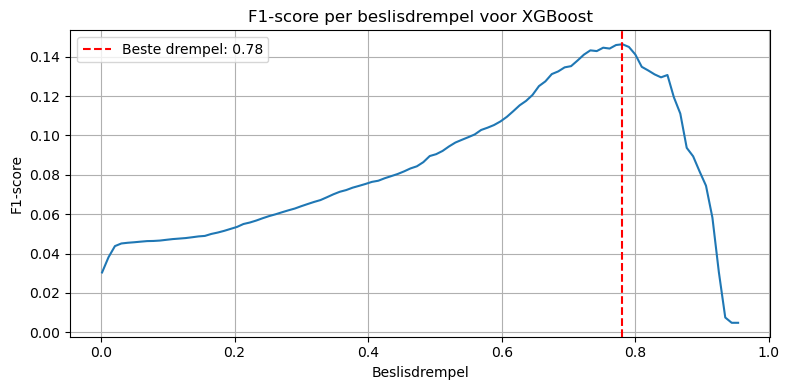

In [51]:
results = best_xgb_model.cv_results_
best_threshold = best_xgb_model.best_threshold_

plt.figure(figsize=(8, 4))
plt.plot(results["thresholds"], results["scores"])
plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Beste drempel: {best_threshold:.2f}",
)
plt.xlabel("Beslisdrempel")
plt.ylabel("F1-score")
plt.title("F1-score per beslisdrempel voor XGBoost")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


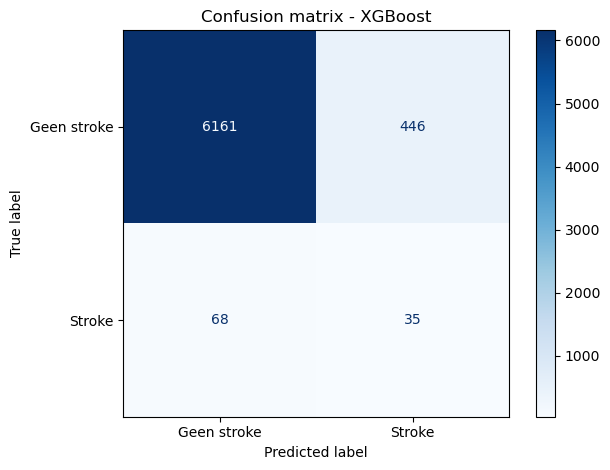

In [52]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    values_format="d",
    cmap="Blues",
)
plt.title("Confusion matrix - XGBoost")
plt.tight_layout()
plt.show()


In [53]:
submission_xgb = maak_submission(
    best_xgb_model,
    X,
    y,
    test,
    tests_ids,
    "../submission_xgb.csv",
)


Opgeslagen: ../submission_xgb.csv
Scoremethode: predict_proba
Gebruikte drempel: 0.780854
Aantal positieve voorspellingen: 699


#### Resultaten XGBoost

De beste instellingen volgens cross-validation zijn:

| Hyperparameter | Beste waarde |
|---|---|
| n_estimators | 100 |
| learning_rate | 0,1 |
| max_depth | 2 |
| reg_lambda | 5 |
| Sampling | RandomOverSampler |
| Beslisdrempel | 0,7809 |

De gemiddelde CV-F1 is **0,1495**. Op de validatieset behalen we een F1-score van **0,1199**, een precision van 0,0728 en een recall van 0,3398.

We hebben dezelfde twee samplingtechnieken als bij GBDT vergeleken:

| Samplingtechniek | Beste gemiddelde CV-F1 |
|---|---:|
| RandomOverSampler | **0,1495** |
| RandomUnderSampler | 0,1441 |

RandomOverSampler behaalde de hoogste CV-F1 binnen onze onderzochte instellingen.

Daarnaast koos de GridSearchCV voor `reg_lambda=5`. Dit betekent dat sterkere L2-regularisatie op de bladscores binnen de geteste configuraties het beste resultaat opleverde.

Op Kaggle behaalde XGBoost een Public F1 van **0,09230**.

Hoewel XGBoost lokaal een relatief hoge CV-F1 behaalt, is de Kaggle-score lager dan die van KNN.

## 3.7 Zelf samengesteld ensemble

### 3.7.1 Werking en modelkeuze

Een ensemble combineert meerdere machinelearningmodellen om één uiteindelijke voorspelling te maken. Het doel is om de sterke punten van verschillende modellen te benutten. Omdat modellen verschillende patronen kunnen herkennen en verschillende fouten kunnen maken, kan hun combinatie betere resultaten opleveren.

Voor ons zelf samengestelde ensemble gebruiken we drie modellen:

- **KNN:** vergelijkt patiënten op basis van de afstand tussen hun kenmerken.
- **Logistic Regression:** voorspelt op basis van een lineaire combinatie van kenmerken.
- **XGBoost:** combineert meerdere beslisbomen die opeenvolgend voorspellingen proberen te verbeteren.

We hebben deze modellen gekozen omdat ze op verschillende manieren voorspellingen maken. Hierdoor onderzoeken we of de modellen elkaar kunnen aanvullen.

Daarnaast ondersteunen alle drie de modellen `predict_proba()`. Hiermee kunnen we Soft Voting toepassen.

### Soft Voting

Bij Soft Voting combineren we de voorspelde scores van meerdere modellen in plaats van uitsluitend hun voorspelde klassen te tellen.

Bij gelijke gewichten gebruiken we:

$$
P = \frac{P_{KNN} + P_{LR} + P_{XGB}}{3}
$$

Bij verschillende stemgewichten wordt dit:

$$
P = \frac{w_1 P_{KNN} + w_2 P_{LR} + w_3 P_{XGB}}{w_1 + w_2 + w_3}
$$

Hierbij zijn $P_{\text{KNN}}$, $P_{\text{LR}}$ en $P_{\text{XGB}}$ de voorspelde scores voor klasse 1. De gewichten $w_1$, $w_2$ en $w_3$ bepalen hoeveel invloed ieder model op de gecombineerde score krijgt.

De gecombineerde score wordt vervolgens vergeleken met een beslisdrempel. Wanneer de score gelijk aan of hoger dan deze drempel is, voorspelt het ensemble klasse 1 (stroke).

We kiezen Soft Voting omdat we hiermee niet alleen rekening houden met de voorspelde klassen, maar ook met de scores van de modellen. Daarnaast kunnen we onderzoeken of sommige modellen meer invloed moeten krijgen dan andere.

<small>Formules gemaakt door ChatGPT ([OpenAI, z.d.-b](https://chatgpt.com/share/6aca0a1c-1304-83eb-ae42-ec6f6a9375df)).</small><br>
Bron: ([scikit-learn developers, z.d.-v](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html)).

### 3.7.2 Training en optimalisatie

We gebruiken de eerder geselecteerde beste modelpipelines van KNN, Logistic Regression en XGBoost. Deze behouden hun preprocessing, samplingtechnieken en modelhyperparameters.

We beginnen met een Soft Voting Ensemble met gelijke stemgewichten `[1,1,1]`.

Daarna vergelijken we verschillende stemgewichten met `GridSearchCV` en 5-fold stratified cross-validation. Als evaluatiemetric gebruiken we de F1-score.

Daarnaast gebruiken we `TunedThresholdClassifierCV` met interne 3-fold cross-validation om de beste beslisdrempel voor het gecombineerde ensemble te bepalen.

De ensemble gebruikt de samplingtechnieken van de afzonderlijke basismodellen binnen de trainingsfolds. De beslisdrempel wordt voor het gecombineerde ensemble geoptimaliseerd en niet afzonderlijk opnieuw voor ieder basismodel.

Bronnen:
- ([scikit-learn developers, z.d.-f](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html))
- ([scikit-learn developers, z.d.-j](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html))
- ([scikit-learn developers, z.d.-e](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html))

Gemiddelde CV-F1: 0.1374
Standaarddeviatie: 0.0133
Beslisdrempel: 0.7743
Validatie-F1: 0.1336
Precision: 0.0811
Recall: 0.3786


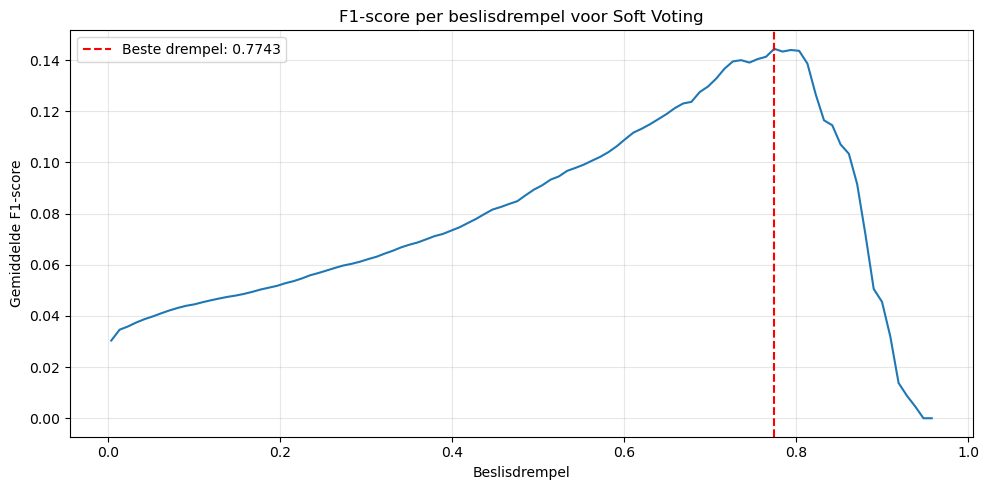

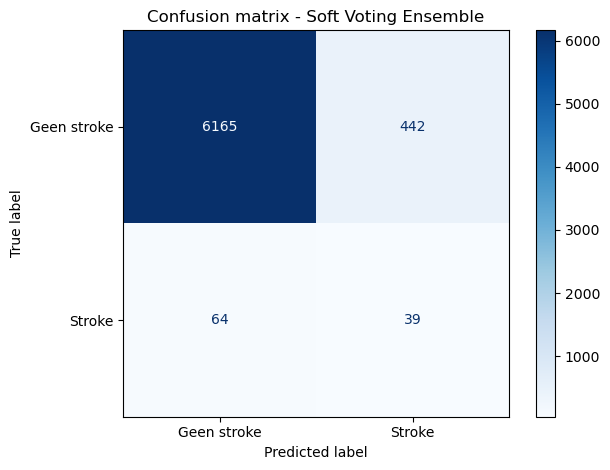

In [54]:

# 3.7 Soft Voting Ensemble: KNN + Logistic Regression + XGBoost

from sklearn.base import clone
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    TunedThresholdClassifierCV,
    cross_val_score
)
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    ConfusionMatrixDisplay
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Gebruik de beste pipelines van de drie modellen
knn_basis = clone(best_model.estimator_)
lr_basis = clone(best_lr_model.estimator_)
xgb_basis = clone(best_xgb_model.estimator_)

# Verwijder ongebruikte l1_ratio indien nodig
if lr_basis.get_params().get("model__penalty", "l2") != "elasticnet":
    lr_basis.set_params(model__l1_ratio=None)

# Combineer de modellen met gelijke gewichten
soft_ensemble = VotingClassifier(
    estimators=[
        ("knn", knn_basis),
        ("lr", lr_basis),
        ("xgb", xgb_basis)
    ],
    voting="soft",
    weights=[1, 1, 1],
    n_jobs=1
)

# Optimaliseer de beslisdrempel
soft_threshold = TunedThresholdClassifierCV(
    estimator=soft_ensemble,
    scoring="f1",
    response_method="predict_proba",
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    store_cv_results=True
)

# 5-fold cross-validation
scores = cross_val_score(
    soft_threshold,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=1,
    error_score="raise"
)

print("Gemiddelde CV-F1:", round(scores.mean(), 4))
print("Standaarddeviatie:", round(scores.std(), 4))

# Train het ensemble op de ontwikkeldata
soft_threshold.fit(X_train, y_train)

# Evaluatie op de validatieset
voorspellingen = soft_threshold.predict(X_test)

print("Beslisdrempel:", round(soft_threshold.best_threshold_, 4))
print("Validatie-F1:", round(f1_score(y_test, voorspellingen), 4))
print("Precision:", round(precision_score(y_test, voorspellingen), 4))
print("Recall:", round(recall_score(y_test, voorspellingen), 4))

# F1-score per beslisdrempel
resultaten = soft_threshold.cv_results_

plt.figure(figsize=(10, 5))
plt.plot(resultaten["thresholds"], resultaten["scores"])
plt.axvline(
    soft_threshold.best_threshold_,
    color="red",
    linestyle="--",
    label=f"Beste drempel: {soft_threshold.best_threshold_:.4f}"
)

plt.title("F1-score per beslisdrempel voor Soft Voting")
plt.xlabel("Beslisdrempel")
plt.ylabel("Gemiddelde F1-score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    voorspellingen,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    values_format="d",
    cmap="Blues"
)

plt.title("Confusion matrix - Soft Voting Ensemble")
plt.tight_layout()
plt.show()


In [55]:

# Hyperparametertuning Soft Voting Ensemble

from sklearn.model_selection import GridSearchCV

# Volgorde: KNN, Logistic Regression, XGBoost
gewicht_grid = {
    "estimator__weights": [
        [1, 1, 1],
        [2, 1, 1],
        [1, 2, 1],
        [1, 1, 2],
        [2, 2, 1],
        [3, 2, 1]
    ]
}

soft_search = GridSearchCV(
    estimator=clone(soft_threshold),
    param_grid=gewicht_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

soft_search.fit(X_train, y_train)

# Vergelijk de resultaten
resultaten = pd.DataFrame(soft_search.cv_results_)

display(
    resultaten[[
        "param_estimator__weights",
        "mean_test_score",
        "std_test_score"
    ]]
    .sort_values("mean_test_score", ascending=False)
    .round(4)
)

print("Beste gewichten:", soft_search.best_params_)
print("Beste CV-F1:", round(soft_search.best_score_, 4))
print("Beste drempel:",
      round(soft_search.best_estimator_.best_threshold_, 4))


Fitting 5 folds for each of 6 candidates, totalling 30 fits


,param_estimator__weights,mean_test_score,std_test_score
2,"[1, 2, 1]",0.1453,0.0137
3,"[1, 1, 2]",0.1446,0.0099
4,"[2, 2, 1]",0.1400,0.0129
0,"[1, 1, 1]",0.1374,0.0133
5,"[3, 2, 1]",0.1334,0.0157
1,"[2, 1, 1]",0.1334,0.0130


Beste gewichten: {'estimator__weights': [1, 2, 1]}
Beste CV-F1: 0.1453
Beste drempel: 0.7859


In [57]:
submission_soft = maak_submission(
    soft_threshold,
    X,
    y,
    test,
    tests_ids,
    "../submission_soft_voting_gelijk1.csv",
)

Opgeslagen: ../submission_soft_voting_gelijk1.csv
Scoremethode: predict_proba
Gebruikte drempel: 0.774339
Aantal positieve voorspellingen: 627


### 3.7.3 Resultaten en conclusie

We hebben met GridSearchCV verschillende stemgewichten voor ons Soft Voting Ensemble onderzocht.

De volgorde van de gewichten is KNN, Logistic Regression en XGBoost.

**Resultaten cross-validation**

| Stemgewichten | Gemiddelde CV-F1 | Standaarddeviatie |
|---|---:|---:|
| [1,1,1] | 0,1374 | 0,0133 |
| [2,1,1] | 0,1334 | 0,0130 |
| **[1,2,1]** | **0,1453** | 0,0137 |
| [1,1,2] | 0,1446 | 0,0099 |
| [2,2,1] | 0,1400 | 0,0129 |
| [3,2,1] | 0,1334 | 0,0157 |

Volgens cross-validation behaalt het ensemble met stemgewichten `[1,2,1]` de hoogste gemiddelde F1-score van 0,1453.

Hierbij krijgt Logistic Regression tweemaal zoveel gewicht als KNN en XGBoost. De optimale beslisdrempel voor deze configuratie is 0,7859.

Bij gelijke stemgewichten `[1,1,1]` bedraagt de gemiddelde CV-F1 0,1374. Op de validatieset behalen we met deze configuratie een F1-score van 0,1336, een precision van 0,0811 en een recall van 0,3786.

De bijbehorende optimale beslisdrempel is 0,7743.

**Kaggle-resultaten van eerdere experimenten**

We hebben daarnaast meerdere eerdere configuraties van Soft Voting op Kaggle onderzocht.

| Configuratie | Kaggle Public F1 |
|---|---:|
| Gelijke gewichten [1,1,1] | **0,11796** |
| XGBoost dubbel [1,1,2] | 0,10526 |
| Gewichten [3,2,1] | 0,11486 |

# 4. Conclusie en advies

## 4.1 Vergelijking van modellen en ensembles

Tijdens deze opdracht hebben we verschillende classificatiemodellen onderzocht om strokegevallen te voorspellen. Voor ieder model hebben we hyperparametertuning en cross-validation toegepast, en onderzocht hoe we met de ongebalanceerde dataset kunnen omgaan.

Onderstaande tabel laat de resultaten zien van de modellen die we hebben ontwikkeld.

| Model | CV-F1 | Validatie-F1 | Kaggle Public F1 |
|---|---:|---:|---:|
| **KNN** | 0,1257 | 0,1240 | **0,13071** |
| Logistic Regression | 0,1499 | 0,1090 | 0,09966 |
| SVM | **0,1567** | 0,1319 | 0,09470 |
| Decision Tree | 0,1520 | 0,0971 | 0,07272 |
| Random Forest | 0,1434 | 0,1109 | 0,08370 |
| GBDT | 0,1437 | 0,1311 | 0,09882 |
| XGBoost | 0,1495 | 0,1199 | 0,09230 |
| Soft Voting Ensemble | 0,1374 | **0,1336** | 0,11796 |

### Vergelijking van de prestaties

SVM behaalt met 0,1567 de hoogste gemiddelde F1-score tijdens cross-validation.

Op de aparte validatieset presteert het huidige Soft Voting Ensemble met 0,1336 het beste van de modellen die we in deze notebookversie hebben geëvalueerd. Het verschil met SVM (0,1319) en GBDT (0,1311) is echter klein.

Op Kaggle behaalt KNN de hoogste Public F1-score van 0,13071.

De resultaten laten zien dat de rangorde van de modellen verschilt per evaluatiemethode. Een model dat tijdens cross-validation het beste presteert, behaalt niet ook de hoogste score op de Kaggle Public Leaderboard.

Een mogelijke verklaring is dat de dataset weinig positieve strokegevallen bevat. Daardoor kan de F1-score sterk worden beïnvloed door een klein aantal correcte of incorrecte voorspellingen.

Daarnaast hebben we tijdens het project meerdere configuraties en beslisdrempels onderzocht. Hierdoor moeten we rekening houden met het risico op overfitting tijdens modelselectie.

We kunnen op basis van deze resultaten niet concluderen dat één algoritme onder alle omstandigheden beter is dan de andere modellen.

## 4.2 Beste model

Welk model het beste presteert, hangt af van de evaluatiemethode die we gebruiken.

SVM behaalt de hoogste gemiddelde F1-score tijdens cross-validation (0,1567). Op onze aparte validatieset behaalt het huidige Soft Voting Ensemble de hoogste F1-score (0,1336).

**Voor de Kaggle-competitie kiezen we KNN als ons beste model**, omdat dit model met een Public F1-score van 0,13071 het hoogste resultaat heeft behaald van onze ingezonden modellen.

De beste instellingen van KNN zijn:

| Hyperparameter | Waarde |
|---|---|
| n_neighbors | 21 |
| p | 1 (Manhattan) |
| weights | distance |
| Sampling | RandomUnderSampler |
| Beslisdrempel | 0,8081 |

Het model gebruikt de Manhattan-afstand om vergelijkbare patiënten te vinden. Door `weights="distance"` krijgen de dichtstbijzijnde buren meer invloed op de voorspelling.

Met RandomUnderSampler wordt de verhouding tussen de twee klassen tijdens training aangepast. Hierdoor krijgen de strokegevallen relatief meer invloed, al gaat er ook informatie uit de meerderheidsklasse verloren.

De beslisdrempel is met cross-validation geoptimaliseerd op de F1-score.

We hebben daarnaast onderzocht of leeftijd zwaarder laten meewegen de prestaties van KNN zou verbeteren. Hoewel de lokale CV-F1 hierdoor steeg, daalde de Kaggle-score. Daarom behouden we de oorspronkelijke configuratie.

KNN is hiermee ons beste model op de Kaggle Public Leaderboard, maar dat betekent niet automatisch dat het ook het meest geschikte model is voor gebruik in de gezondheidszorg.

## 4.3 Overige overwegingen

Naast de F1-score spelen verschillende andere factoren een rol bij het kiezen van een machinelearningmodel. Vooral bij medische toepassingen is het belangrijk om kritisch naar de betrouwbaarheid en de gevolgen van voorspellingen te kijken.

### False positives en false negatives

Een false positive betekent dat het model een patiënt als strokegeval classificeert terwijl de werkelijke klasse 0 is. Dit kan leiden tot onnodige vervolgonderzoeken, extra werk voor zorgverleners en mogelijk ongerustheid bij patiënten.

Een false negative betekent dat een werkelijk strokegeval niet wordt herkend. Wanneer een model in de praktijk als risicosignalering wordt gebruikt, kan dit ertoe leiden dat een patiënt ten onrechte als laag risico wordt beoordeeld.

### Uitlegbaarheid

Bij medische toepassingen is het belangrijk dat artsen begrijpen waarom een model een bepaalde voorspelling maakt.

Logistic Regression is relatief eenvoudig uit te leggen, omdat het model werkt met gewichten per kenmerk. Bij Decision Trees kunnen de beslisregels zichtbaar worden gemaakt.

KNN is ook begrijpelijk op hoofdlijnen, maar een voorspelling hangt af van de geselecteerde buren en de afstandsberekening. Bij Random Forest, XGBoost en andere ensembles is het meestal ingewikkelder om een individuele voorspelling volledig te verklaren.

Een model met een iets hogere F1-score hoeft daardoor niet automatisch de beste keuze te zijn.

### Betrouwbaarheid en generaliseerbaarheid

Tijdens onze experimenten zagen we dat de scores konden verschillen tussen cross-validation, onze validatieset en Kaggle.

Daarnaast hebben we de modellen op verschillende train-validatiesplitsingen onderzocht. Hierbij zagen we dat de F1-scores afhankelijk waren van welke patiënten in de validatieset terechtkwamen.

Dit betekent dat onze resultaten onzekerheid bevatten. Voordat we een model in een echte zorgomgeving kunnen gebruiken, moet het worden getest op onafhankelijke gegevens van andere patiënten en bij voorkeur andere zorginstellingen.

### Klasse-onbalans

Omdat slechts 1,54% van de patiënten een stroke heeft gehad, is het voor de modellen moeilijk om betrouwbare positieve voorspellingen te doen.

Een model kan een hoge accuracy behalen door bijna altijd geen stroke te voorspellen. Daarom hebben we vooral gekeken naar precision, recall en F1.

### Bias en representativiteit

Het is belangrijk dat het model voor verschillende groepen patiënten voldoende betrouwbaar is.

De huidige evaluatie laat niet zien of de prestaties voor bijvoorbeeld verschillende leeftijds- of gendergroepen gelijk zijn. Een model kan gemiddeld redelijk presteren, maar voor specifieke groepen veel slechter zijn.

### Conclusie

Bij de keuze van een model moeten we dus niet uitsluitend naar de hoogste F1-score kijken. Uitlegbaarheid, stabiliteit, foutkosten, representativiteit en de mogelijkheid om het model verantwoord te onderhouden zijn ook heel belangrijk.

Voor medische toepassingen wegen deze aspecten extra zwaar, omdat verkeerde voorspellingen heftige gevolgen kunnen hebben voor patiënten.

## 4.4 Advies aan artsen

**Voor verder onderzoek adviseren we om KNN als een van de belangrijkste kandidaten te behouden**, omdat dit model in onze Kaggle-experimenten het beste heeft gepresteerd.

Voordat een model in de zorgpraktijk kan worden toegepast, is aanvullend onderzoek nodig. Het model moet onder andere worden gevalideerd op onafhankelijke patiëntgegevens, worden onderzocht op mogelijke bias en worden beoordeeld op de gevolgen van false positive en false negative voorspellingen.

Onze conclusie is dat de modellen interessante patronen kunnen herkennen, maar dat de huidige prestaties nog onvoldoende zijn om betrouwbare individuele medische voorspellingen te doen.

## Verantwoording generatieve AI

### Main codex chat:

**AI-tool:** OpenAI Codex  
**Modelversie:** Sol 5.6 / Sol 6 / Sol 6.1  
**Gesprek:** https://chatgpt.com/s/cx_6aca1353637c8191af4b69d39af6d148

**Gebruik van AI:**

Tijdens deze opdracht hebben we Codex gebruikt voor ondersteuning bij het ontwikkelen, controleren en verbeteren van het Jupyter Notebook. Hierbij is AI onder andere gebruikt voor theoretische uitleg, Python-code, het onderzoeken van fouten en het evalueren van modelresultaten.
Daarnaast hebben we Codex gebruikt voor het controleren van de opdrachtvereisten en het bijwerken van de projectplanning.


**Relevante prompts**

| Prompt(s) | Onderwerp | Gebruik in project/notebook |
|---|---|---|
| 1–2 | Opdrachtanalyse en notebookstructuur | Opdrachtvereisten controleren, hoofdstukindeling en taakverdeling opstellen |
| 4, 7, 22, 25, 27 | Projectdocumentatie | README en `pva.md` opstellen en bijwerken |
| 5 | Standaardisatie | Uitleg, bronnen en preprocessing-pipeline in §1.11 |
| 8 | Train- en validatiestrategie | Advies en codevoorbeeld voor §2.1 |
| 9 | Evaluatiemetrics en baseline | Uitleg confusion matrix en eerste Logistic Regression-baseline in §2.2 |
| 10 | Algemene modelaanpak | Eerste tekst voor §3.1 |
| 11–12 | KNN ontwikkelen | Theorie en eerste GridSearchCV-code voor §3.2 |
| 13, 16–18 | KNN-submissions en beslisdrempel | Drempeloptimalisatie, submissioncode en correctie van de KNN-submission |
| 19–20 | KNN-resultaten verklaren | Uitleg van de KNN-instellingen en behaalde Kaggle-score in §3.2.3 |
| 26 | KNN, SVM en herbruikbare functies | KNN-afstandsformules, SVM-rekenvoorbeeld en functies `toon_resultaten()` en `maak_submission()` |
| 28 | GBDT en XGBoost | Theorie, onderbouwing, modelpipelines en tuningcode in §3.6.2 en §3.6.3 |
| 30 | XGBoost aanvullen | Ontbrekende trainingscode voor XGBoost in §3.6.3 |
| 23–24, 32–33 | Projectcontrole | Controle van modellen, code, resultaten en opdrachtvereisten |

**Verantwoording**

De AI-ondersteuning is gebruikt bij het schrijven en controleren van onderdelen van het project. De code en resultaten zijn waar mogelijk gecontroleerd door het uitvoeren van de modellen en het vergelijken van de uitkomsten. Alles is gecontroleerd door of Tijn of Yorrick, zie PVA voor wie wat heeft gecontroleerd.

De theoretische uitleg is daarnaast onderbouwd met officiële documentatie van onder andere scikit-learn, imbalanced-learn en XGBoost. Deze bronnen staan afzonderlijk in de referentielijst.

### Losse AI chats:
 - Formules eigen ensable: OpenAI (sol 5.6). (z.d.-b). *Ensembleformule met KNN LR XGBoost* [ChatGPT-gesprek]. https://chatgpt.com/share/6aca0a1c-1304-83eb-ae42-ec6f6a9375df
 - Formules Logistic Regression: OpenAI (sol 5.6). (z.d.-a). *Berekeningen Logistic Regression* [ChatGPT-gesprek]. https://chatgpt.com/share/6ac26f99-0190-83eb-b42b-13209d314d0c
 - SVM-code: Anthropic. (z.d.). *SVM-code op basis van LR en KNN* [Claude-gesprek]. https://claude.ai/share/e793cc47-1e24-4f48-8f86-6ba82efbbd7e


## Bronnen standaardisatie

scikit-learn developers. (z.d.-a). *StandardScaler*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

scikit-learn developers. (z.d.-b). *Importance of feature scaling*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html

scikit-learn developers. (z.d.-c). *LogisticRegression*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

scikit-learn developers. (z.d.-d). *Common pitfalls and recommended practices*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/common_pitfalls.html

scikit-learn developers. (z.d.-p). *Classification metrics*. Scikit-learn. Geraadpleegd op 25 september 2026, van https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics

scikit-learn developers. (z.d.-r). *KNeighborsClassifier*. Scikit-learn. Geraadpleegd op 25 september 2026, van https://scikit-learn.org/1.6/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

scikit-learn developers. (z.d.-j). *TunedThresholdClassifierCV*. Scikit-learn. Geraadpleegd op 25 september 2026, van https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html

imbalanced-learn developers. (z.d.-c). *RandomUnderSampler*. Imbalanced-learn. Geraadpleegd op 25 september 2026, van https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.RandomUnderSampler.html



## Bronnen afstandsmaten en SVM

scikit-learn developers. (z.d.-q). *DistanceMetric*. Scikit-learn 1.6. Geraadpleegd op 8 oktober 2026, van https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.DistanceMetric.html

scikit-learn developers. (z.d.-u). *Support Vector Machines*. Scikit-learn 1.6. Geraadpleegd op 8 oktober 2026, van https://scikit-learn.org/1.6/modules/svm.html


## Bronnen GBDT en XGBoost

scikit-learn developers. (z.d.-w). *Gradient boosting*. Scikit-learn 1.6. Geraadpleegd op 8 oktober 2026, van https://scikit-learn.org/1.6/modules/ensemble.html#gradient-tree-boosting

scikit-learn developers. (z.d.-x). *GradientBoostingClassifier*. Scikit-learn 1.6. Geraadpleegd op 8 oktober 2026, van https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html

XGBoost developers. (z.d.-a). *Introduction to Boosted Trees*. XGBoost 3.0.5. Geraadpleegd op 8 oktober 2026, van https://xgboost.readthedocs.io/en/release_3.0.0/tutorials/model.html

XGBoost developers. (z.d.-b). *XGBoost Parameters*. XGBoost 3.0.5. Geraadpleegd op 8 oktober 2026, van https://xgboost.readthedocs.io/en/release_3.0.0/parameter.html

XGBoost developers. (z.d.-c). *Using the Scikit-Learn Estimator Interface*. XGBoost 3.0.5. Geraadpleegd op 8 oktober 2026, van https://xgboost.readthedocs.io/en/release_3.0.0/python/sklearn_estimator.html


## Aanvullende bronnen uit de cellen

scikit-learn developers. (z.d.-e). *StratifiedKFold*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html

scikit-learn developers. (z.d.-f). *GridSearchCV*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

scikit-learn developers. (z.d.-g). *RandomForestClassifier*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

scikit-learn developers. (z.d.-h). *Tuning the decision threshold for class prediction*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/classification_threshold.html

scikit-learn developers. (z.d.-i). *train_test_split*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

scikit-learn developers. (z.d.-k). *Nearest Neighbors*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/neighbors.html

scikit-learn developers. (z.d.-l). *OneHotEncoder*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html

scikit-learn developers. (z.d.-m). *Metrics and scoring: quantifying the quality of predictions*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/model_evaluation.html

scikit-learn developers. (z.d.-n). *Imputation of missing values*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/impute.html

scikit-learn developers. (z.d.-o). *Preprocessing data*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/preprocessing.html

scikit-learn developers. (z.d.-s). *Decision Trees*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/tree.html

scikit-learn developers. (z.d.-t). *Forests of randomized trees*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees

scikit-learn developers. (z.d.-v). *VotingClassifier*. Scikit-learn. Geraadpleegd op 10 oktober 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html

imbalanced-learn developers. (z.d.-a). *Pipeline*. Imbalanced-learn. Geraadpleegd op 10 oktober 2026, van https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html

imbalanced-learn developers. (z.d.-b). *RandomOverSampler*. Imbalanced-learn. Geraadpleegd op 10 oktober 2026, van https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.RandomOverSampler.html

SciPy developers. (z.d.-a). *chi2_contingency*. SciPy. Geraadpleegd op 10 oktober 2026, van https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html

SciPy developers. (z.d.-b). *pearsonr*. SciPy. Geraadpleegd op 10 oktober 2026, van https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html

Matplotlib developers. (z.d.-a). *matplotlib.pyplot.boxplot*. Matplotlib. Geraadpleegd op 10 oktober 2026, van https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html

Google developers. (z.d.-a). *Classification: Accuracy, recall, precision, and related metrics*. Google for Developers. Geraadpleegd op 10 oktober 2026, van https://developers.google.com/machine-learning/crash-course/classification/accuracy-precision-recall
